# Drug Review Analysis: Improved ML Training
## 01. Project Overview
**Goal:** predict the rating-derived patient experience (Negative: 1–3, Neutral: 4–6,
Positive: 7–10) and the original integer rating (1–10), using review text.
These are the two tasks in the original Colab, not independently annotated sentiment.

**Sources:** [Original Colab](https://colab.research.google.com/drive/1t8LBcEYfcSBrAZpptJ-XtMjma9cWmp2O),
its supplied execution PDF, and the two local CSVs. The retrieved notebook is preserved
in `original/Drug_Review.ipynb`. Its instructions and claims are reference material;
this notebook verifies them against data and executed results.

**Protocol:** reproduce the old grouped split first; then compare models on one
deduplicated development split. Tune with three-fold grouped CV using training data only.
Select using validation macro-F1 for experience and validation MAE for rating.
Finally evaluate on provided-test texts absent from the entire original training CSV.
This is a reserved holdout for this workflow, not a new external dataset.

The output dictionary keeps the original drug, condition, experience, confidence, and
integer-rating fields. Drug and condition remain display metadata, not predictive inputs.
These models describe reported experiences; they do not support medication recommendations.

**Run:** upload both CSVs to Colab or point `DATA_DIR` at a mounted Drive folder, then
choose Runtime → Run all. CPU is sufficient. Full-data CV takes several minutes or longer
depending on the machine. All metrics and charts below are calculated by code, not hard-coded.

**Update:** requested Optuna, bagging, boosting and voting experiments are in Section 21. The earlier final test is now previously viewed; extension assessment is explicitly labeled repeated. Current selected artifacts are saved separately in `models_ensemble`.

**Public repository edition:** patient-review row outputs are omitted to respect the dataset distribution terms. Aggregate experimental scores and charts remain. Obtain the dataset directly from its source and execute the cells to inspect genuine rows locally; do not upload those generated review outputs publicly.

## 02. Import Libraries
We use sparse TF-IDF features and linear models because this is a text problem with
more than 160,000 rows. Section 21 additionally tests sparse bagging and feature-selected AdaBoost with a bounded CPU budget. Colab normally includes these dependencies.
If an import fails, install `pandas numpy scipy scikit-learn matplotlib joblib`.

In [1]:
import os
# Limit numerical-library threads to keep CPU experiments predictable.
os.environ["OMP_NUM_THREADS"] = "2"
os.environ["OPENBLAS_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
import re, html, json, time, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy
import joblib
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, RandomizedSearchCV, cross_validate
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score, log_loss,
    mean_absolute_error, mean_squared_error, make_scorer)

SEED = 42
np.random.seed(SEED)
DATA_DIR = Path('.')  # In Colab: Path('/content') or your mounted Google Drive folder.
OUTPUT_DIR = Path('models_improved')
RESULTS_DIR = Path('experiments')
OUTPUT_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.titlesize': 13,
                     'axes.titleweight': 'bold', 'font.size': 10, 'figure.dpi': 110})
environment = {'python': platform.python_version(), 'numpy': np.__version__,
               'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
               'scipy': scipy.__version__, 'joblib': joblib.__version__}
print(environment)

{'python': '3.14.2', 'numpy': '2.4.2', 'pandas': '3.0.1', 'scikit-learn': '1.8.0', 'scipy': '1.17.1', 'joblib': '1.5.3'}


## 03. Dataset Loading
We preserve the supplied train/test files. The test CSV is loaded for schema and
duplicate-overlap auditing only; its labels do not enter model selection or tuning.
We verify the column names instead of assuming that the first column is an input feature.

**Colab steps:** upload this notebook, run from the top, and select **both** `drugsComTrain_raw.csv` and `drugsComTest_raw.csv` together when the upload dialog appears. Keep the original filenames. A new runtime needs the files uploaded again unless you store them in Google Drive and update `DATA_DIR`. Download trained artifacts before the temporary runtime ends.

In [2]:
train_path = DATA_DIR / 'drugsComTrain_raw.csv'
test_path = DATA_DIR / 'drugsComTest_raw.csv'
if not train_path.exists() or not test_path.exists():
    from google.colab import files
    print('Upload drugsComTrain_raw.csv and drugsComTest_raw.csv.')
    files.upload()
assert train_path.exists() and test_path.exists(), 'Check DATA_DIR and the uploaded filenames.'
raw_train = pd.read_csv(train_path)
raw_test = pd.read_csv(test_path)
for frame in [raw_train, raw_test]:
    if frame.columns[0].lower().startswith('unnamed'):
        frame.rename(columns={frame.columns[0]: 'uniqueID'}, inplace=True)
required_columns = ['uniqueID', 'drugName', 'condition', 'review', 'rating', 'date', 'usefulCount']
assert set(required_columns) == set(raw_train.columns) == set(raw_test.columns)
file_hashes = {path.name: hashlib.sha256(path.read_bytes()).hexdigest()
               for path in [train_path, test_path]}
print('Train:', raw_train.shape, '| Provided test:', raw_test.shape)
print('SHA256:', file_hashes)

Train: (161297, 7) | Provided test: (53766, 7)
SHA256: {'drugsComTrain_raw.csv': 'bc0902b21af0db5b99568a7639ed5f7dad3494a8186a20d05c5b4016c6caedf4', 'drugsComTest_raw.csv': 'dfdaa5245b3f24e2af2b26ff4b21b798159c2d54184da9846c9458b83d1897c3'}


## 04. Dataset Understanding
`review` is the only model input. `rating` supplies both targets and is never a feature.
`uniqueID` identifies records; `usefulCount` is feedback collected after publication.
`date`, `drugName`, and `condition` support dataset analysis but are excluded from this
text-only inference contract. A numeric ID or helpfulness count would be a poor shortcut.

In [3]:
display(raw_train.head(3))
display(raw_train.dtypes.rename('dtype').to_frame())
display(raw_train.describe(include='all').T)
print('Rating values:', sorted(raw_train['rating'].dropna().unique()))
print('Date range:', pd.to_datetime(raw_train['date'], format='%d-%b-%y').agg(['min', 'max']))

## 05. Exploratory Data Analysis
We audit missingness, invalid values, text duplication, and class balance before deciding
what to change. Duplicate IDs and duplicate text are different problems: two different
IDs can contain the same review. EDA uses training labels only.

,train,provided_test
rows,161297,53766
columns,7,7
missing_condition,899,295
missing_review,0,0
full_duplicate_rows,0,0
duplicate_ids,0,0
duplicate_raw_text,48968,5486
blank_review,0,0
invalid_rating,0,0
invalid_date,0,0


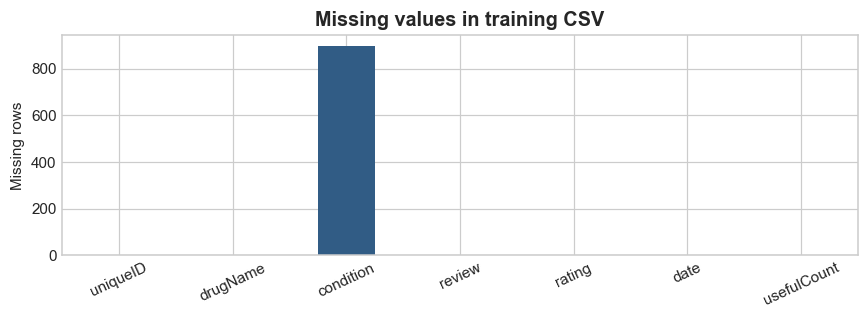

**Finding:** 899 conditions are missing. There are 0 missing reviews. Missing metadata need not cause us to discard valid review text.

In [4]:
def audit(frame):
    dates = pd.to_datetime(frame['date'], format='%d-%b-%y', errors='coerce')
    return {'rows': len(frame), 'columns': len(frame.columns),
        'missing_condition': int(frame['condition'].isna().sum()),
        'missing_review': int(frame['review'].isna().sum()),
        'full_duplicate_rows': int(frame.duplicated().sum()),
        'duplicate_ids': int(frame['uniqueID'].duplicated().sum()),
        'duplicate_raw_text': int(frame['review'].duplicated().sum()),
        'blank_review': int(frame['review'].fillna('').str.strip().eq('').sum()),
        'invalid_rating': int((~frame['rating'].isin(range(1, 11))).sum()),
        'invalid_date': int(dates.isna().sum()),
        'negative_useful_count': int((frame['usefulCount'] < 0).sum()),
        'condition_artifacts': int(frame['condition'].fillna('').str.contains('</span>', regex=False).sum()),
        'html_entity_reviews': int(frame['review'].fillna('').str.contains('&#039;|&amp;|&quot;', regex=True).sum()),
        'unique_drugs': int(frame['drugName'].nunique()),
        'unique_conditions': int(frame['condition'].nunique())}

audit_table = pd.DataFrame({'train': audit(raw_train), 'provided_test': audit(raw_test)})
display(audit_table)
audit_table.to_csv(RESULTS_DIR / 'data_audit.csv')
fig, ax = plt.subplots(figsize=(8, 3))
raw_train.isna().sum().plot.bar(ax=ax, color='#315c85', rot=25)
ax.set(title='Missing values in training CSV', ylabel='Missing rows')
plt.tight_layout(); plt.show()
display(Markdown(f"**Finding:** {raw_train.condition.isna().sum():,} conditions are missing. "
                 f"There are {raw_train.review.isna().sum():,} missing reviews. "
                 'Missing metadata need not cause us to discard valid review text.'))

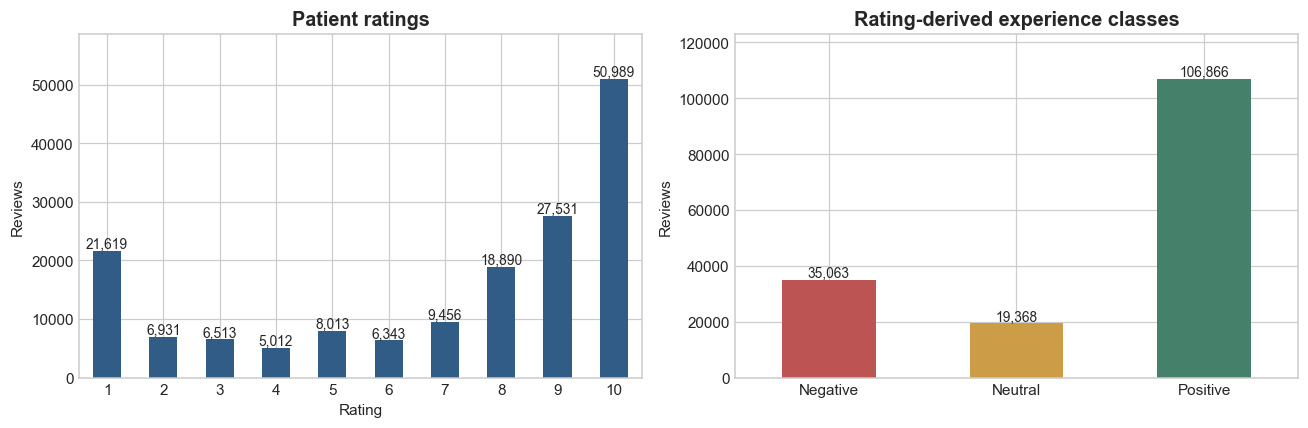

**Finding:** Positive accounts for 66.3%, Neutral for 12.0%. Macro-F1 gives equal importance to each class; accuracy alone favors the majority.

In [5]:
rating_counts = raw_train.rating.value_counts().sort_index()
experience_counts = pd.Series(np.where(raw_train.rating <= 3, 'Negative',
    np.where(raw_train.rating <= 6, 'Neutral', 'Positive'))).value_counts().reindex(['Negative','Neutral','Positive'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rating_counts.plot.bar(ax=axes[0], color='#315c85', rot=0)
axes[0].set(title='Patient ratings', xlabel='Rating', ylabel='Reviews')
experience_counts.plot.bar(ax=axes[1], color=['#bd5454','#cc9d46','#45816a'], rot=0)
axes[1].set(title='Rating-derived experience classes', ylabel='Reviews')
for ax in axes:
    for bar in ax.patches:
        ax.annotate(f'{int(bar.get_height()):,}', (bar.get_x()+bar.get_width()/2, bar.get_height()),
                    ha='center', va='bottom', fontsize=9)
    ax.margins(y=0.15)
plt.tight_layout(); plt.show()
display(Markdown(f"**Finding:** Positive accounts for {experience_counts['Positive']/len(raw_train):.1%}, "
                 f"Neutral for {experience_counts['Neutral']/len(raw_train):.1%}. "
                 'Macro-F1 gives equal importance to each class; accuracy alone favors the majority.'))

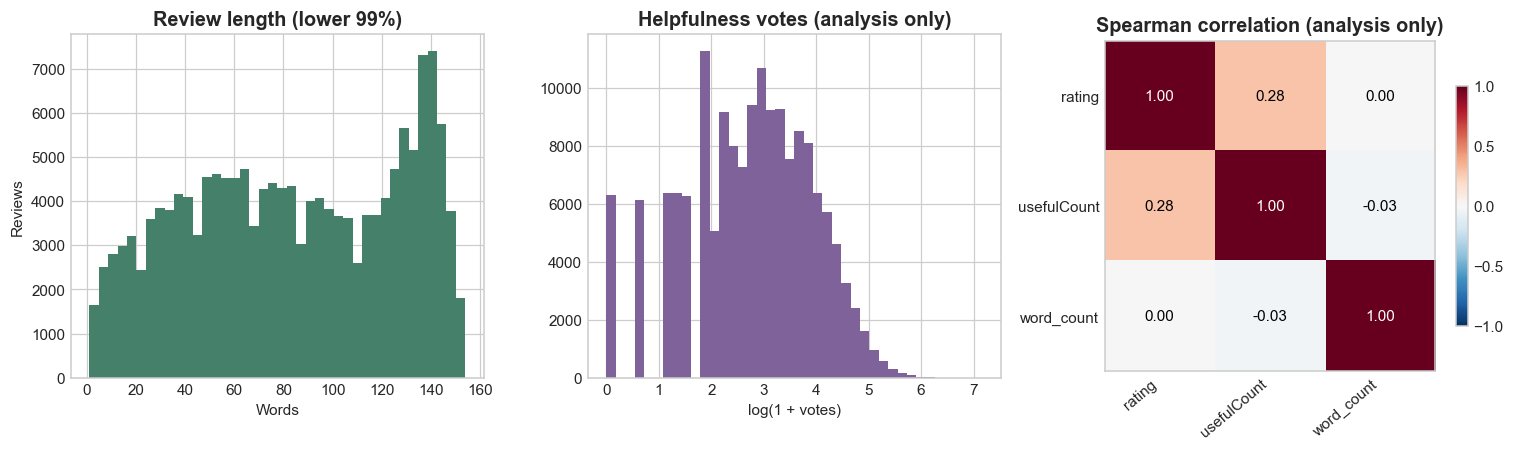

,count,mean,std,min,25%,50%,75%,max
rating,161297.0,6.994377,3.272329,1.0,5.0,8.0,10.0,10.0
usefulCount,161297.0,28.004755,36.403742,0.0,6.0,16.0,36.0,1291.0
word_count,161297.0,84.699802,45.044833,1.0,48.0,84.0,126.0,1894.0


**Interpretation:** review length and votes have long tails. The length histogram displays the lower 99% only; no training rows are removed. We keep valid long reviews; length alone is not a reason to remove a patient report. Votes are excluded from prediction because they would not exist when a new review is submitted. Correlation is not causation.

In [6]:
eda = raw_train[['rating', 'usefulCount']].copy()
eda['word_count'] = raw_train.review.fillna('').str.split().str.len()
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
display_limit = eda.word_count.quantile(0.99)
axes[0].hist(eda.loc[eda.word_count <= display_limit, 'word_count'], bins=40, color='#45816a')
axes[0].set(title='Review length (lower 99%)', xlabel='Words', ylabel='Reviews')
axes[1].hist(np.log1p(eda.usefulCount), bins=40, color='#80629b')
axes[1].set(title='Helpfulness votes (analysis only)', xlabel='log(1 + votes)')
correlation = eda.corr(method='spearman')
image = axes[2].imshow(correlation, vmin=-1, vmax=1, cmap='RdBu_r')
axes[2].set_xticks(range(3), correlation.columns, rotation=40, ha='right')
axes[2].set_yticks(range(3), correlation.columns)
axes[2].set_title('Spearman correlation (analysis only)')
axes[2].grid(False)
for i in range(3):
    for j in range(3):
        axes[2].text(j, i, f'{correlation.iloc[i,j]:.2f}', ha='center', va='center', color='white' if abs(correlation.iloc[i,j]) > 0.6 else 'black')
fig.colorbar(image, ax=axes[2], shrink=0.7)
plt.tight_layout(); plt.show()
display(eda.describe().T)
display(Markdown('**Interpretation:** review length and votes have long tails. The length histogram displays the lower 99% only. We keep valid long reviews; '
                 'length alone is not a reason to remove a patient report. Votes are excluded from prediction '
                 'because they would not exist when a new review is submitted. Correlation is not causation.'))

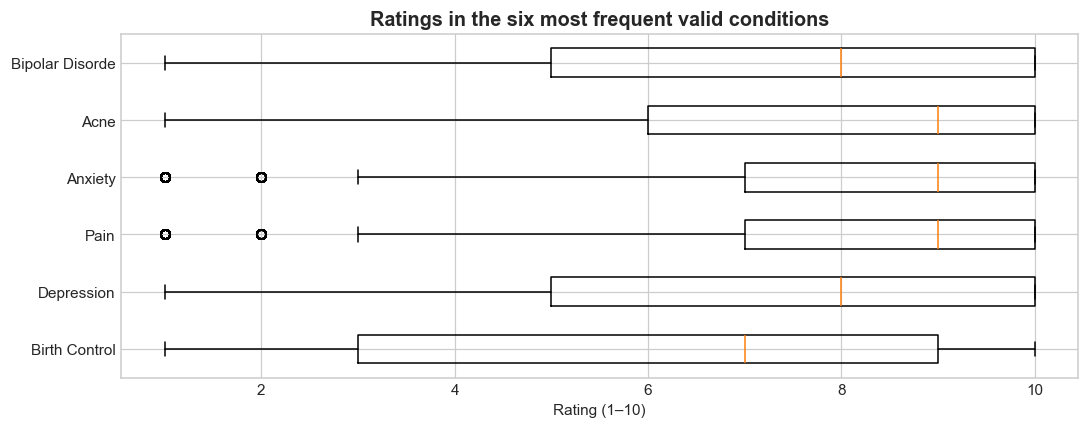

**Interpretation:** these distributions describe this self-selected review dataset. They do not compare clinical effectiveness. Corrupt condition strings are excluded from this chart only.

In [7]:
top_conditions = raw_train.loc[~raw_train.condition.fillna('').str.contains('</span>', regex=False),
                              'condition'].value_counts().head(6).index
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([raw_train.loc[raw_train.condition.eq(c), 'rating'].values for c in top_conditions],
           orientation='horizontal', tick_labels=top_conditions)
ax.set(title='Ratings in the six most frequent valid conditions', xlabel='Rating (1–10)')
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation:** these distributions describe this self-selected review dataset. '
                 'They do not compare clinical effectiveness. Corrupt condition strings are excluded from this chart only.'))

## 06. Data Cleaning
We decode HTML, strip wrapping quotes, and normalize whitespace exactly as in the original.
We retain negation, stop words, numbers, and long reviews. We correct missing/corrupt
condition values for display only. For improved training, each `(normalized text, rating)`
pair gets one vote; conflicting ratings are retained and grouped, not relabeled to improve scores.
Lowercase text defines a conservative leakage group because TF-IDF itself lowercases words.

In [3]:
def clean_review(text):
    text = html.unescape(str(text))
    text = text.replace('\r', ' ').replace('\n', ' ')
    text = re.sub(r'^"|"$', '', text.strip())
    return re.sub(r'\s+', ' ', text).strip()

train_data = raw_train.copy()
test_data = raw_test.copy()
for frame in [train_data, test_data]:
    frame['review_clean'] = frame.review.fillna('').map(clean_review)
    frame['text_group'] = frame.review_clean.str.lower()
    frame['condition'] = frame.condition.fillna('Unknown')
    corrupt_condition = frame.condition.str.contains('</span>', regex=False)
    frame.loc[corrupt_condition, 'condition'] = 'Unknown'
    frame['date_parsed'] = pd.to_datetime(frame.date, format='%d-%b-%y', errors='coerce')
    frame['experience'] = np.where(frame.rating <= 3, 'Negative',
                                   np.where(frame.rating <= 6, 'Neutral', 'Positive'))
    frame['word_count'] = frame.review_clean.str.split().str.len()

valid_training = train_data.review_clean.ne('') & train_data.rating.isin(range(1, 11))
development = train_data.loc[valid_training].drop_duplicates(['text_group', 'rating']).copy()
development.reset_index(drop=True, inplace=True)
conflicting_train_groups = int((development.groupby('text_group').rating.nunique() > 1).sum())
print('Invalid training rows removed:', int((~valid_training).sum()))
print('Repeated text-rating pairs removed:', int(valid_training.sum() - len(development)))
print('Retained development examples:', len(development))
print('Conflicting rating groups retained:', conflicting_train_groups)
display(train_data[['review', 'review_clean']].head(2))

In [4]:
raw_overlap = set(raw_train.review) & set(raw_test.review)
overlapping_test = test_data.text_group.isin(set(train_data.text_group))
# No test labels are examined here. Membership is determined by text only.
novel_test = test_data.loc[~overlapping_test].copy()
novel_test = novel_test.loc[novel_test.review_clean.ne('')].drop_duplicates(['text_group', 'rating'])
print('Exact raw shared strings:', len(raw_overlap))
print('Share of unique raw test texts:', len(raw_overlap) / raw_test.review.nunique())
print('Normalized overlapping test rows:', int(overlapping_test.sum()))
print('Reserved non-overlapping test examples:', len(novel_test))
leakage_audit = {'raw_shared_strings': len(raw_overlap),
    'raw_overlap_fraction_unique_test': len(raw_overlap)/raw_test.review.nunique(),
    'normalized_overlap_test_rows': int(overlapping_test.sum()),
    'reserved_test_examples': len(novel_test), 'development_examples': len(development),
    'conflicting_training_groups': conflicting_train_groups}
(RESULTS_DIR / 'leakage_audit.json').write_text(json.dumps(leakage_audit, indent=2))
display(Markdown('**Finding:** the original test CSV contains many texts already present in training. '
                 'Its full score is a legacy benchmark, not a clean estimate of new-review performance. '
                 'We reserve only non-overlapping texts for final testing. Exact normalization does not detect paraphrases.'))

Exact raw shared strings: 32131
Share of unique raw test texts: 0.6655136702568352
Normalized overlapping test rows: 32228
Reserved non-overlapping test examples: 16141


**Finding:** the original test CSV contains many texts already present in training. Its full score is a legacy benchmark, not a clean estimate of new-review performance. We reserve only non-overlapping texts for final testing. Exact normalization does not detect paraphrases.

## 07. Feature Engineering & Preprocessing
TF-IDF converts words and word pairs into sparse numeric features and applies L2 row
normalization. We do not scale sparse text with StandardScaler. Word pairs preserve
phrases such as “not helpful”. The baseline limits vocabulary to 40,000 terms (`min_df=3`);
the richer candidate allows 80,000 (`min_df=2`). A Pipeline fits vocabulary and IDF
inside each training/CV fold. LabelEncoder has the original alphabetical class order.

Pipeline caching reuses TF-IDF only when training rows, targets, and settings match. Different CV folds get separate fits. Temporary cache files in experiments/tfidf_cache can be removed after the run.

`min_df=2` keeps a term only if it occurs in at least two training reviews; `max_features` limits vocabulary size. TF-IDF downweights terms common across reviews.

In [5]:
label_encoder = LabelEncoder().fit(['Negative', 'Neutral', 'Positive'])
classes = label_encoder.classes_
# Small helpers avoid repeating vectorizer settings and metric definitions.
def text_pipeline(model, max_features=40000, min_df=3):
    # Reuse identical training-fold TF-IDF work across classifiers/search trials.
    return Pipeline([('tfidf', TfidfVectorizer(max_features=max_features,
        ngram_range=(1, 2), min_df=min_df, sublinear_tf=True)), ('model', model)],
        memory=str(RESULTS_DIR / 'tfidf_cache'))

def classification_metrics(model, texts, labels):
    # Transform each set once rather than tokenizing it again for probabilities.
    if isinstance(model, Pipeline) and 'tfidf' in model.named_steps:
        features = model.named_steps['tfidf'].transform(texts)
        estimator = model.named_steps['model']
    else:
        features, estimator = texts, model
    predictions = estimator.predict(features)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predictions, average='macro', zero_division=0)
    scores = estimator.predict_proba(features) if hasattr(estimator, 'predict_proba') else estimator.decision_function(features)
    binary_labels = label_binarize(labels, classes=[0, 1, 2])
    # Per-class one-vs-rest AUC also works with uncalibrated SVM margins.
    auc = np.mean([roc_auc_score(binary_labels[:, i], scores[:, i]) for i in range(3)])
    return {'Accuracy': accuracy_score(labels, predictions), 'Precision': precision,
            'Recall': recall, 'F1': f1, 'ROC-AUC': auc}

def rating_metrics(model, texts, labels):
    predictions = model.predict(texts).astype(int)
    return {'MAE': mean_absolute_error(labels, predictions),
            'RMSE': np.sqrt(mean_squared_error(labels, predictions)),
            'Exact accuracy': accuracy_score(labels, predictions),
            'Within-1 accuracy': np.mean(np.abs(np.asarray(labels)-predictions) <= 1)}

## 08. Train/Validation/Test Split
The baseline reproduction uses the original 15% GroupShuffleSplit on case-sensitive
cleaned text. The improved comparison uses the same seed and 15% group holdout after
deduplication, grouping lowercase cleaned text. These are separate protocols, so their
scores cannot be subtracted as if they were the same experiment.

All improved candidates share identical training and validation rows. Three stratified
group folds are created within training only. Neither validation nor test is fitted by
TF-IDF. The reserved test CSV subset has no normalized text in the entire training CSV.

In [6]:
original_splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
original_train_idx, original_val_idx = next(original_splitter.split(train_data, groups=train_data.review_clean))
original_train = train_data.iloc[original_train_idx].copy()
original_val = train_data.iloc[original_val_idx].copy()
splitter = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
train_idx, val_idx = next(splitter.split(development, groups=development.text_group))
training = development.iloc[train_idx].copy()
validation = development.iloc[val_idx].copy()
X_train, X_val = training.review_clean, validation.review_clean
y_train = label_encoder.transform(training.experience)
y_val = label_encoder.transform(validation.experience)
yr_train, yr_val = training.rating.to_numpy(), validation.rating.to_numpy()
assert not set(training.text_group) & set(validation.text_group)
assert not set(development.text_group) & set(novel_test.text_group)
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_folds = list(cv.split(X_train, y_train, groups=training.text_group))
for fold_train, fold_valid in cv_folds:
    assert not set(training.iloc[fold_train].text_group) & set(training.iloc[fold_valid].text_group)
    assert set(y_train[fold_train]) == set(y_train[fold_valid]) == {0,1,2}
split_counts = {'original_train': len(original_train), 'original_validation': len(original_val),
                'train': len(training), 'validation': len(validation), 'reserved_test': len(novel_test)}
print(split_counts)
display(pd.DataFrame({'training': pd.Series(y_train).value_counts(normalize=True),
                      'validation': pd.Series(y_val).value_counts(normalize=True)}).rename(index=dict(enumerate(classes))))
pd.concat([training[['uniqueID']].assign(split='train'), validation[['uniqueID']].assign(split='validation'),
           novel_test[['uniqueID']].assign(split='reserved_test')]).to_csv(RESULTS_DIR/'split_manifest.csv', index=False)

{'original_train': 137147, 'original_validation': 24150, 'train': 95528, 'validation': 16853, 'reserved_test': 16141}


,training,validation
Positive,0.663449,0.662137
Negative,0.216900,0.217409
Neutral,0.119651,0.120453


## 09. Original Model Baseline
We reproduce TF-IDF (40,000 word/bigram terms, `min_df=3`, `sublinear_tf=True`) and
LogisticRegression (`C=1`, `class_weight='balanced'`, `max_iter=1000`, seed 42).
The original 10-class rating model uses the same settings. This is the original
algorithm/settings/split under the locally installed library versions, not a claim
of bitwise reproduction of scikit-learn 1.6.1.

**Historical PDF only:** printed sentiment report rounds accuracy to 0.74 and
macro-F1 to 0.63; prose quotes 0.7434/0.6341. Rating output records MAE 1.6040,
exact accuracy 0.3648, within-1 accuracy 0.6434. Some benchmark prose and hard-coded
comparisons disagree with actual notebook output. The following numbers are newly executed.

Reproduction seconds: 565.4


,Accuracy,Precision,Recall,F1,ROC-AUC,MAE,RMSE,Exact accuracy,Within-1 accuracy
experience_train,0.872261,0.799700,0.883698,0.829172,0.971805,NaN,NaN,NaN,NaN
experience_validation,0.743064,0.623949,0.656873,0.633819,0.862681,NaN,NaN,NaN,NaN
rating_train,NaN,NaN,NaN,NaN,NaN,0.851291,1.980208,0.695786,0.816678
rating_validation,NaN,NaN,NaN,NaN,NaN,1.604017,2.579060,0.364803,0.643354


              precision    recall  f1-score   support

    Negative       0.66      0.71      0.69      5187
     Neutral       0.30      0.45      0.36      2907
    Positive       0.91      0.81      0.86     16056

    accuracy                           0.74     24150
   macro avg       0.62      0.66      0.63     24150
weighted avg       0.78      0.74      0.76     24150



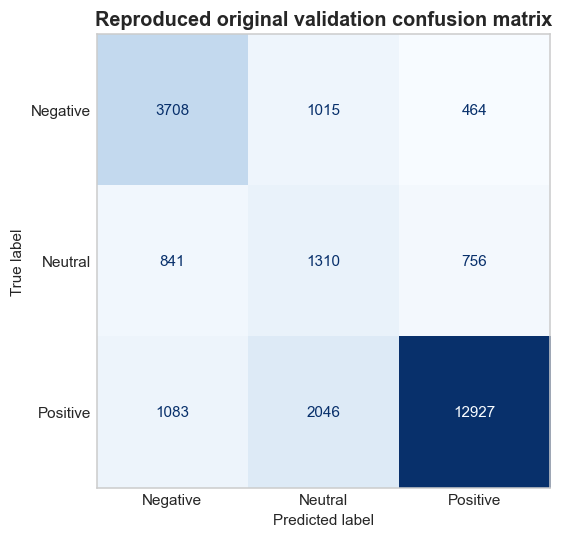

**Interpretation:** this is the reference reproduction. Neutral performance and the training/validation gap can now be inspected from real predictions. The fair baseline below uses the improved data protocol so changes in model settings can be compared directly.

755

In [12]:
start = time.time()
original_experience_model = text_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED))
original_experience_model.fit(original_train.review_clean, label_encoder.transform(original_train.experience))
original_rating_model = text_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED))
original_rating_model.fit(original_train.review_clean, original_train.rating)
original_results = {
    'experience_train': classification_metrics(original_experience_model, original_train.review_clean, label_encoder.transform(original_train.experience)),
    'experience_validation': classification_metrics(original_experience_model, original_val.review_clean, label_encoder.transform(original_val.experience)),
    'rating_train': rating_metrics(original_rating_model, original_train.review_clean, original_train.rating),
    'rating_validation': rating_metrics(original_rating_model, original_val.review_clean, original_val.rating)}
print('Reproduction seconds:', round(time.time()-start, 1))
display(pd.DataFrame(original_results).T)
print(classification_report(label_encoder.transform(original_val.experience),
    original_experience_model.predict(original_val.review_clean), target_names=classes, zero_division=0))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(label_encoder.transform(original_val.experience),
    original_experience_model.predict(original_val.review_clean), display_labels=classes, ax=ax, colorbar=False, cmap='Blues')
ax.grid(False)
ax.set_title('Reproduced original validation confusion matrix')
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation:** this is the reference reproduction. Neutral performance and the '
                 'training/validation gap can now be inspected from real predictions. The fair baseline below '
                 'uses the improved data protocol so changes in model settings can be compared directly.'))
(RESULTS_DIR/'original_reproduction.json').write_text(json.dumps(original_results, indent=2))

## 10. Improved Model Training
We compare the original settings on the common cleaned split, a richer TF-IDF logistic
model, a linear SVM, and Complement Naive Bayes. These are suitable for sparse text.
Balanced weights are a candidate, not a guaranteed improvement. For ratings we compare
the old balanced ten-class classifier with an unweighted richer classifier; ratings are
ordinal, so MAE is the selection metric and exact/within-one accuracy are secondary.

In [13]:
candidates = {
    'Original settings (fair split)': text_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED)),
    'Richer logistic': text_pipeline(LogisticRegression(C=4, max_iter=1000, class_weight='balanced', random_state=SEED), 80000, 2),
    'Linear SVM': text_pipeline(LinearSVC(C=1, class_weight='balanced', random_state=SEED), 80000, 2),
    'Complement NB': text_pipeline(ComplementNB(alpha=0.5), 80000, 2)}
validation_rows = []
for name, model in candidates.items():
    start = time.time()
    model.fit(X_train, y_train)
    training_predictions = model.predict(X_train)
    row = {'Model': name, **classification_metrics(model, X_val, y_val),
           'Train Accuracy': accuracy_score(y_train, training_predictions),
           'Train F1': f1_score(y_train, training_predictions, average='macro'),
           'Fit seconds': time.time()-start}
    validation_rows.append(row)
    print(name, 'validation macro-F1:', round(row['F1'], 4), flush=True)
display(pd.DataFrame(validation_rows))

Original settings (fair split) validation macro-F1: 0.6396


Richer logistic validation macro-F1: 0.6387


Linear SVM validation macro-F1: 0.6272


Complement NB validation macro-F1: 0.5739


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train Accuracy,Train F1,Fit seconds
0,Original settings (fair split),0.743725,0.629782,0.665535,0.639599,0.869690,0.841261,0.788143,58.435515
1,Richer logistic,0.759331,0.629609,0.652716,0.638713,0.864653,0.939620,0.920253,98.084620
2,Linear SVM,0.774462,0.628076,0.627335,0.627164,0.851239,0.976865,0.966758,51.785025
3,Complement NB,0.756542,0.599660,0.596432,0.573865,0.853372,0.817739,0.695729,27.500947


In [14]:
rating_candidates = {
    'Original rating settings (fair split)': text_pipeline(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED)),
    'Unweighted rating logistic': text_pipeline(LogisticRegression(C=4, max_iter=1000, random_state=SEED), 80000, 2)}
rating_rows = []
for name, model in rating_candidates.items():
    model.fit(X_train, yr_train)
    rating_rows.append({'Model': name, **rating_metrics(model, X_val, yr_val),
                        'Train MAE': mean_absolute_error(yr_train, model.predict(X_train))})
display(pd.DataFrame(rating_rows))

,Model,MAE,RMSE,Exact accuracy,Within-1 accuracy,Train MAE
0,Original rating settings (fair split),1.615083,2.599483,0.364327,0.637928,0.979346
1,Unweighted rating logistic,1.526909,2.627161,0.419807,0.679523,0.411848


## 11. Hyperparameter Optimization
We test four reproducibly sampled logistic configurations from `C=[1,4,8]` and
`class_weight=[None,'balanced']`. C controls regularization: larger C permits larger
coefficients. Each of the three folds fits its own TF-IDF vocabulary. Training data only
is used by the search; validation confirms the selected configuration afterward.
We keep the vocabulary settings fixed at 80,000/min_df=2 to bound runtime.
The rating search uses negative MAE (larger is better), not classification accuracy.

In [15]:
parameter_space = {'model__C': [1.0, 4.0, 8.0], 'model__class_weight': [None, 'balanced']}
search = RandomizedSearchCV(
    text_pipeline(LogisticRegression(max_iter=1000, random_state=SEED), 80000, 2),
    parameter_space, n_iter=4, scoring='f1_macro', cv=cv_folds,
    random_state=SEED, n_jobs=1, refit=True, error_score='raise', verbose=1)
search.fit(X_train, y_train)
candidates['Tuned logistic'] = search.best_estimator_
training_predictions = search.predict(X_train)
validation_rows.append({'Model': 'Tuned logistic', **classification_metrics(search.best_estimator_, X_val, y_val),
    'Train Accuracy': accuracy_score(y_train, training_predictions),
    'Train F1': f1_score(y_train, training_predictions, average='macro'),
    'Fit seconds': search.refit_time_})
search_table = pd.DataFrame(search.cv_results_)[['params','mean_test_score','std_test_score','rank_test_score']]
display(search_table.sort_values('rank_test_score'))
print('Chosen experience parameters:', search.best_params_)
search_table.to_csv(RESULTS_DIR/'sentiment_search.csv', index=False)

Fitting 3 folds for each of 4 candidates, totalling 12 fits


,params,mean_test_score,std_test_score,rank_test_score
1,"{'model__class_weight': 'balanced', 'model__C'...",0.639865,0.000502,1
2,"{'model__class_weight': 'balanced', 'model__C'...",0.626369,0.001962,2
3,"{'model__class_weight': None, 'model__C': 4.0}",0.606914,0.001590,3
0,"{'model__class_weight': None, 'model__C': 1.0}",0.585209,0.003026,4


Chosen experience parameters: {'model__class_weight': 'balanced', 'model__C': 1.0}


**One additional text-feature experiment:** the initial alternatives did not clearly beat the fair baseline. Before final testing, we combine word phrases and character fragments (3–5 characters inside word boundaries) to represent contractions and spelling variations. The same training/validation rows and grouped CV folds are used. C=1 and balanced weights are fixed; test scores play no role in this choice.

In [16]:
from sklearn.pipeline import FeatureUnion
character_features = FeatureUnion([
    ('word', TfidfVectorizer(max_features=80000, ngram_range=(1,2), min_df=2, sublinear_tf=True)),
    ('character', TfidfVectorizer(analyzer='char_wb', ngram_range=(3,5),
                                min_df=5, max_features=20000, sublinear_tf=True))])
character_model = Pipeline([('tfidf',character_features),
    ('model',LogisticRegression(C=1,max_iter=1000,class_weight='balanced',random_state=SEED))],
    memory=str(RESULTS_DIR/'tfidf_cache'))
start = time.time()
character_model.fit(X_train,y_train)
training_predictions = character_model.predict(X_train)
candidates['Word + character logistic'] = character_model
character_row = {'Model':'Word + character logistic', **classification_metrics(character_model,X_val,y_val),
    'Train Accuracy':accuracy_score(y_train,training_predictions),
    'Train F1':f1_score(y_train,training_predictions,average='macro'), 'Fit seconds':time.time()-start}
validation_rows.append(character_row)
(RESULTS_DIR/'character_experiment.json').write_text(json.dumps(character_row,indent=2))
print('Additional training-only character experiment:',character_row,flush=True)


Additional training-only character experiment: {'Model': 'Word + character logistic', 'Accuracy': 0.7525069720524535, 'Precision': 0.6342812197005737, 'Recall': 0.6674166251650151, 'F1': 0.6447763401240192, 'ROC-AUC': np.float64(0.8704872649531259), 'Train Accuracy': 0.8731262038355246, 'Train F1': 0.831684944922575, 'Fit seconds': 357.2751851081848}



In [17]:
rating_search = RandomizedSearchCV(
    text_pipeline(LogisticRegression(max_iter=1000, random_state=SEED), 80000, 2),
    parameter_space, n_iter=4, scoring=make_scorer(mean_absolute_error, greater_is_better=False),
    cv=cv_folds, random_state=SEED, n_jobs=1, refit=True, error_score='raise', verbose=1)
rating_search.fit(X_train, yr_train)
rating_candidates['Tuned rating logistic'] = rating_search.best_estimator_
rating_rows.append({'Model': 'Tuned rating logistic',
    **rating_metrics(rating_search.best_estimator_, X_val, yr_val),
    'Train MAE': mean_absolute_error(yr_train, rating_search.predict(X_train))})
display(pd.DataFrame(rating_search.cv_results_)[['params','mean_test_score','std_test_score','rank_test_score']])
print('Chosen rating parameters:', rating_search.best_params_)
pd.DataFrame(rating_search.cv_results_).drop(columns=['param_model__C','param_model__class_weight']).to_csv(
    RESULTS_DIR/'rating_search.csv', index=False)

Fitting 3 folds for each of 4 candidates, totalling 12 fits


,params,mean_test_score,std_test_score,rank_test_score
0,"{'model__class_weight': None, 'model__C': 1.0}",-1.625461,0.006470,4
1,"{'model__class_weight': 'balanced', 'model__C'...",-1.615369,0.011060,3
2,"{'model__class_weight': 'balanced', 'model__C'...",-1.558757,0.017228,2
3,"{'model__class_weight': None, 'model__C': 4.0}",-1.556057,0.002871,1


Chosen rating parameters: {'model__class_weight': None, 'model__C': 4.0}


## 12. Cross-Validation
Three folds test stability on unseen text groups. Every candidate uses the same folds
and fold-local preprocessing. We reuse search fold scores for the tuned candidate.
These tuned scores helped select hyperparameters, so they have selection optimism;
the untouched validation split is the common confirmation. This is not nested CV.
For rating we use the same grouped folds to keep task comparisons aligned.

Original settings (fair split) CV: [0.6376 0.6364 0.6375]


Richer logistic CV: [0.633  0.6314 0.6365]


Linear SVM CV: [0.619  0.6151 0.624 ]


Complement NB CV: [0.5735 0.5713 0.5724]


Tuned logistic CV: [0.6403 0.6392 0.6402]


Word + character logistic CV: [0.6357 0.6341 0.6358]


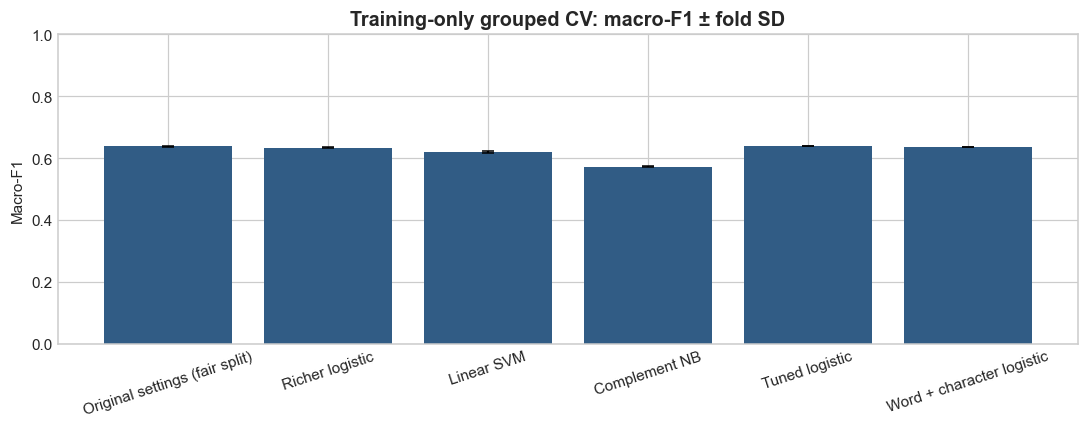

**Interpretation:** fold SD measures variability across these three partitions, not a confidence interval. Large training scores cannot replace these generalization checks.

In [18]:
cv_scores = {}
for name, model in candidates.items():
    if name == 'Tuned logistic':
        best = search.best_index_
        scores = np.array([search.cv_results_[f'split{i}_test_score'][best] for i in range(3)])
    else:
        scores = cross_validate(clone(model), X_train, y_train, cv=cv_folds,
                                scoring='f1_macro', n_jobs=1, error_score='raise')['test_score']
    cv_scores[name] = scores.tolist()
    print(name, 'CV:', scores.round(4), flush=True)
comparison = pd.DataFrame(validation_rows)
comparison['CV Score'] = comparison.Model.map(lambda name: np.mean(cv_scores[name]))
comparison['CV SD'] = comparison.Model.map(lambda name: np.std(cv_scores[name]))
comparison['Notes'] = comparison.Model.map(lambda name: 'CV used for tuning; validation confirms' if name=='Tuned logistic'
                                          else 'Same grouped folds; macro metrics')
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(comparison.Model, comparison['CV Score'], yerr=comparison['CV SD'], capsize=4, color='#315c85')
ax.set(title='Training-only grouped CV: macro-F1 ± fold SD', ylabel='Macro-F1', ylim=(0,1))
ax.tick_params(axis='x', rotation=18)
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation:** fold SD measures variability across these three partitions, '
                 'not a confidence interval. Large training scores cannot replace these generalization checks.'))

In [20]:
rating_cv_scores = {}
for name, model in rating_candidates.items():
    if name == 'Tuned rating logistic':
        best = rating_search.best_index_
        scores = -np.array([rating_search.cv_results_[f'split{i}_test_score'][best] for i in range(3)])
    elif name == 'Unweighted rating logistic':
        # Reuse the identical model configuration and folds already executed in the search.
        parameters = {'model__C':4.0,'model__class_weight':None}
        matching_trial = list(rating_search.cv_results_['params']).index(parameters)
        scores = -np.array([rating_search.cv_results_[f'split{i}_test_score'][matching_trial] for i in range(3)])
    else:
        scores = -cross_validate(clone(model), X_train, yr_train, cv=cv_folds,
            scoring=make_scorer(mean_absolute_error, greater_is_better=False),
            n_jobs=1, error_score='raise')['test_score']
    rating_cv_scores[name] = scores.tolist()
rating_comparison = pd.DataFrame(rating_rows)
rating_comparison['CV MAE'] = rating_comparison.Model.map(lambda name: np.mean(rating_cv_scores[name]))
rating_comparison['CV SD'] = rating_comparison.Model.map(lambda name: np.std(rating_cv_scores[name]))
display(rating_comparison)

Reusing the already executed rating-search fold scores: {'model__C': 4, 'model__class_weight': None}


,Model,MAE,RMSE,Exact accuracy,Within-1 accuracy,Train MAE,CV MAE,CV SD
0,Original rating settings (fair split),1.615083,2.599483,0.364327,0.637928,0.979346,1.631459,0.014894
1,Unweighted rating logistic,1.526909,2.627161,0.419807,0.679523,0.411848,1.556057,0.002871
2,Tuned rating logistic,1.526909,2.627161,0.419807,0.679523,0.411848,1.556057,0.002871


## 13. Model Evaluation
We report macro precision, recall, F1, and macro one-vs-rest ROC-AUC. AUC evaluates ranking;
it does not guarantee calibrated probabilities or high Neutral recall. Precision-recall
curves include each class prevalence as the no-skill reference. The candidate shown
here is selected by validation macro-F1, with CV as supporting evidence.

Accuracy is the fraction correct. Precision asks how many predicted members of a class are correct; recall asks how many actual members were found. F1 balances precision and recall; macro averaging gives each class equal weight. Rating MAE is the average absolute error in rating points. RMSE penalizes large errors more.

Validation-selected experience model: Tuned logistic
              precision    recall  f1-score   support

    Negative       0.67      0.73      0.70      3664
     Neutral       0.32      0.48      0.38      2030
    Positive       0.92      0.81      0.86     11159

    accuracy                           0.75     16853
   macro avg       0.64      0.67      0.65     16853
weighted avg       0.79      0.75      0.77     16853



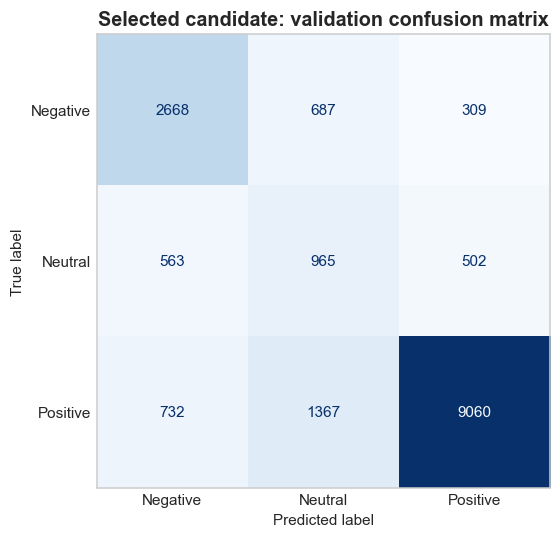

**Finding:** Neutral precision is 0.320 and recall is 0.475. The confusion matrix shows where the minority class is confused. The targets are rating bins; mixed language need not agree with the numerical label.

In [21]:
winner_name = comparison.sort_values(['F1','CV Score'], ascending=False).iloc[0]['Model']
winner = candidates[winner_name]
val_predictions = winner.predict(X_val)
print('Validation-selected experience model:', winner_name)
print(classification_report(y_val, val_predictions, target_names=classes, zero_division=0))
fig, ax = plt.subplots(figsize=(6,5))
ConfusionMatrixDisplay.from_predictions(y_val, val_predictions, display_labels=classes, ax=ax, colorbar=False, cmap='Blues')
ax.grid(False)
ax.set_title('Selected candidate: validation confusion matrix')
plt.tight_layout(); plt.show()
report = classification_report(y_val, val_predictions, target_names=classes, zero_division=0, output_dict=True)
display(Markdown(f"**Finding:** Neutral precision is {report['Neutral']['precision']:.3f} and recall is "
                 f"{report['Neutral']['recall']:.3f}. The confusion matrix shows where the minority class is confused. "
                 'The targets are rating bins; mixed language need not agree with the numerical label.'))

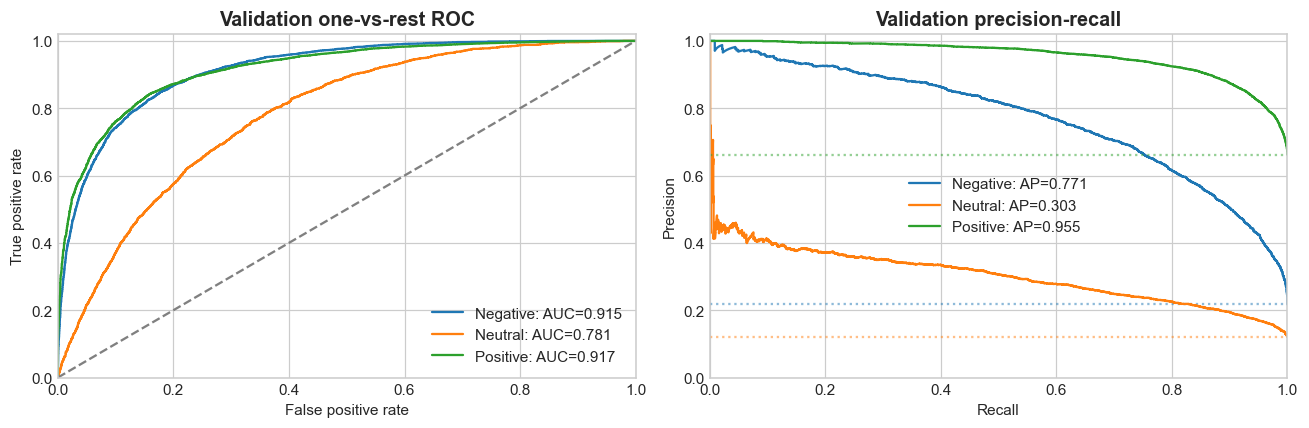

**Interpretation:** each curve measures one class against the other two. Dotted precision lines show class prevalence. Compare Neutral AP with its prevalence, rather than interpreting majority-class accuracy as success on all classes.

In [22]:
val_scores = winner.predict_proba(X_val) if hasattr(winner, 'predict_proba') else winner.decision_function(X_val)
val_binary = label_binarize(y_val, classes=[0,1,2])
fig, axes = plt.subplots(1,2,figsize=(12,4))
for i, name in enumerate(classes):
    fpr, tpr, _ = roc_curve(val_binary[:,i], val_scores[:,i])
    precision, recall, _ = precision_recall_curve(val_binary[:,i], val_scores[:,i])
    auc = roc_auc_score(val_binary[:,i], val_scores[:,i])
    ap = average_precision_score(val_binary[:,i], val_scores[:,i])
    axes[0].plot(fpr,tpr,label=f'{name}: AUC={auc:.3f}')
    line, = axes[1].plot(recall,precision,label=f'{name}: AP={ap:.3f}')
    axes[1].axhline(val_binary[:,i].mean(), color=line.get_color(), linestyle=':', alpha=0.5)
axes[0].plot([0,1],[0,1],'--',color='gray')
axes[0].set(title='Validation one-vs-rest ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='Validation precision-recall', xlabel='Recall', ylabel='Precision')
for ax in axes: ax.legend(); ax.set_xlim(0,1); ax.set_ylim(0,1.02)
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation:** each curve measures one class against the other two. '
                 'Dotted precision lines show class prevalence. Compare Neutral AP with its prevalence, '
                 'rather than interpreting majority-class accuracy as success on all classes.'))

## 14. Model Comparison
Only the common cleaned validation split appears in this table. The historical PDF,
new baseline reproduction, and final holdout are recorded separately. Higher macro-F1
selects the experience model; lower MAE selects the rating model. No test score is used.

,Model,CV Score,CV SD,Accuracy,Precision,Recall,F1,ROC-AUC,Notes
4,Tuned logistic,0.639865,0.000502,0.753160,0.636903,0.671812,0.647833,0.871045,CV used for tuning; validation confirms
5,Word + character logistic,0.635202,0.000792,0.752507,0.634281,0.667417,0.644776,0.870487,Same grouped folds; macro metrics
0,Original settings (fair split),0.637182,0.000520,0.743725,0.629782,0.665535,0.639599,0.869690,Same grouped folds; macro metrics
1,Richer logistic,0.633644,0.002147,0.759331,0.629609,0.652716,0.638713,0.864653,Same grouped folds; macro metrics
2,Linear SVM,0.619390,0.003655,0.774462,0.628076,0.627335,0.627164,0.851239,Same grouped folds; macro metrics
3,Complement NB,0.572401,0.000870,0.756542,0.599660,0.596432,0.573865,0.853372,Same grouped folds; macro metrics


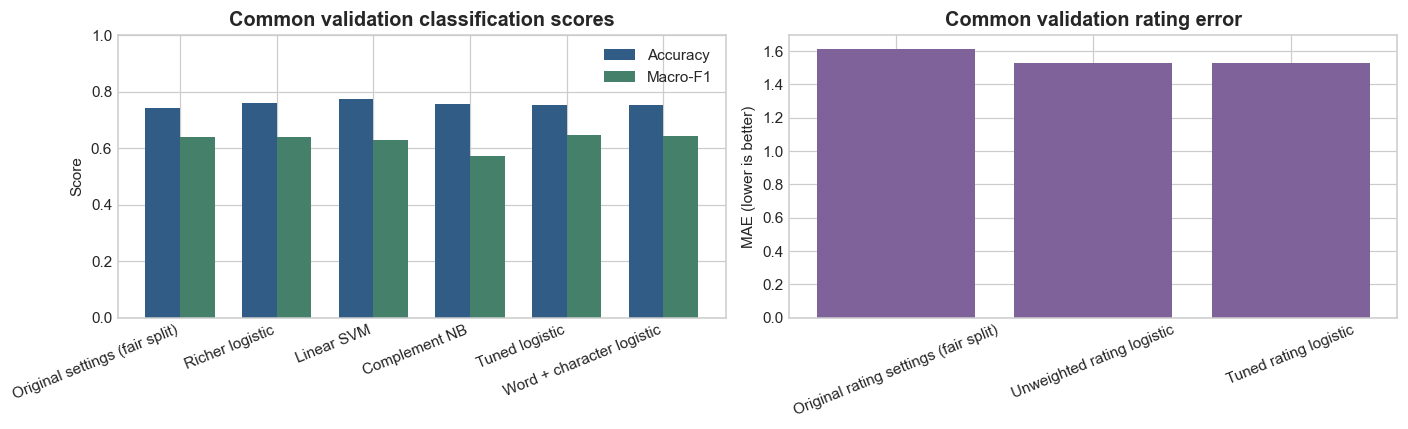

**Measured validation improvement:** macro-F1 0.6396 → 0.6478 (+0.82 percentage points). This is a same-split comparison, not a subtraction from the historical PDF.

In [23]:
display(comparison[['Model','CV Score','CV SD','Accuracy','Precision','Recall','F1','ROC-AUC','Notes']].sort_values('F1',ascending=False))
fig, axes = plt.subplots(1,2,figsize=(13,4))
positions = np.arange(len(comparison))
axes[0].bar(positions-0.18, comparison.Accuracy, 0.36, label='Accuracy', color='#315c85')
axes[0].bar(positions+0.18, comparison.F1, 0.36, label='Macro-F1', color='#45816a')
axes[0].set_xticks(positions,comparison.Model,rotation=22,ha='right')
axes[0].set(title='Common validation classification scores', ylabel='Score', ylim=(0,1)); axes[0].legend()
axes[1].bar(rating_comparison.Model,rating_comparison.MAE,color='#80629b')
axes[1].set(title='Common validation rating error',ylabel='MAE (lower is better)')
axes[1].tick_params(axis='x',rotation=22)
plt.tight_layout(); plt.show()
fair_baseline = comparison.loc[comparison.Model.eq('Original settings (fair split)')].iloc[0]
selected_row = comparison.loc[comparison.Model.eq(winner_name)].iloc[0]
display(Markdown(f"**Measured validation improvement:** macro-F1 {fair_baseline.F1:.4f} → "
                 f"{selected_row.F1:.4f} ({100*(selected_row.F1-fair_baseline.F1):+.2f} percentage points). "
                 'This is a same-split comparison, not a subtraction from the historical PDF.'))
comparison.to_csv(RESULTS_DIR/'model_comparison.csv',index=False)
rating_comparison.to_csv(RESULTS_DIR/'rating_comparison.csv',index=False)

## 15. Feature Importance & Explainability
Linear coefficients show terms associated with each class after controlling for other
terms. They are not clinical causes. If Naive Bayes wins, we show relative log-probability
associations instead. These are global explanations; a word must also occur in a review
to contribute to that particular prediction. SHAP is unnecessary for this simple model.

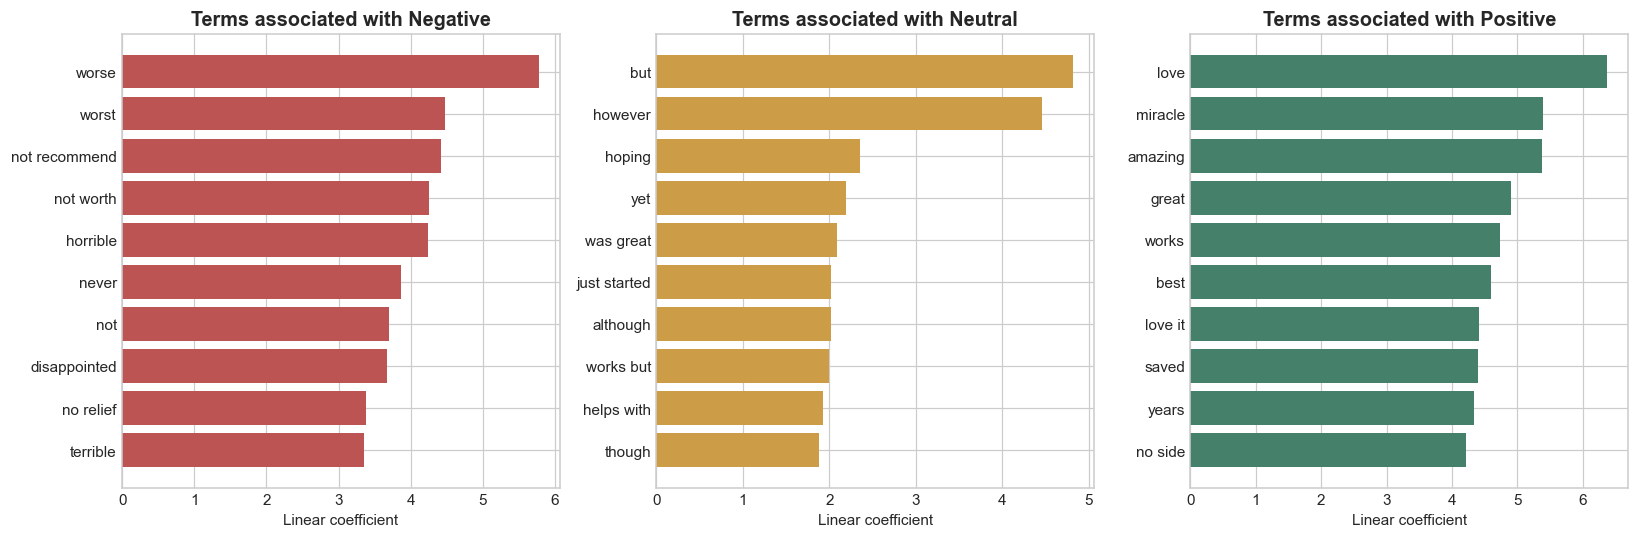

Measured influential terms: {np.str_('Negative'): ['worse', 'worst', 'not recommend', 'not worth', 'horrible', 'never', 'not', 'disappointed', 'no relief', 'terrible'], np.str_('Neutral'): ['but', 'however', 'hoping', 'yet', 'was great', 'just started', 'although', 'works but', 'helps with', 'though'], np.str_('Positive'): ['love', 'miracle', 'amazing', 'great', 'works', 'best', 'love it', 'saved', 'years', 'no side']}


**Interpretation:** read the actual term lists above. Phrase coefficients support keeping negation and contrast words. These associations reflect rating labels in this corpus.

In [24]:
terms = winner.named_steps['tfidf'].get_feature_names_out()
estimator = winner.named_steps['model']
if hasattr(estimator, 'coef_'):
    weights = estimator.coef_
    weight_description = 'Linear coefficient'
else:
    weights = estimator.feature_log_prob_
    weights = weights - weights.mean(axis=0)
    weight_description = 'Relative log-probability association'
fig, axes = plt.subplots(1,3,figsize=(15,5))
top_terms = {}
for i,name in enumerate(classes):
    indices = np.argsort(weights[i])[-10:]
    axes[i].barh(terms[indices],weights[i,indices],color=['#bd5454','#cc9d46','#45816a'][i])
    axes[i].set(title=f'Terms associated with {name}',xlabel=weight_description)
    top_terms[name] = terms[indices[::-1]].tolist()
plt.tight_layout(); plt.show()
print('Measured influential terms:',top_terms)
display(Markdown('**Interpretation:** read the actual term lists above. Phrase coefficients support '
                 'keeping negation and contrast words. These associations reflect rating labels in this corpus.'))

## 16. Overfitting Analysis
These classical models do not expose meaningful epoch-by-epoch accuracy/loss histories.
We show real train/validation metrics instead of invented learning curves. Log loss
is calculated only for models with probabilities. Class weighting can change probability
calibration, so “confidence” is a model score, not a verified probability of correctness.

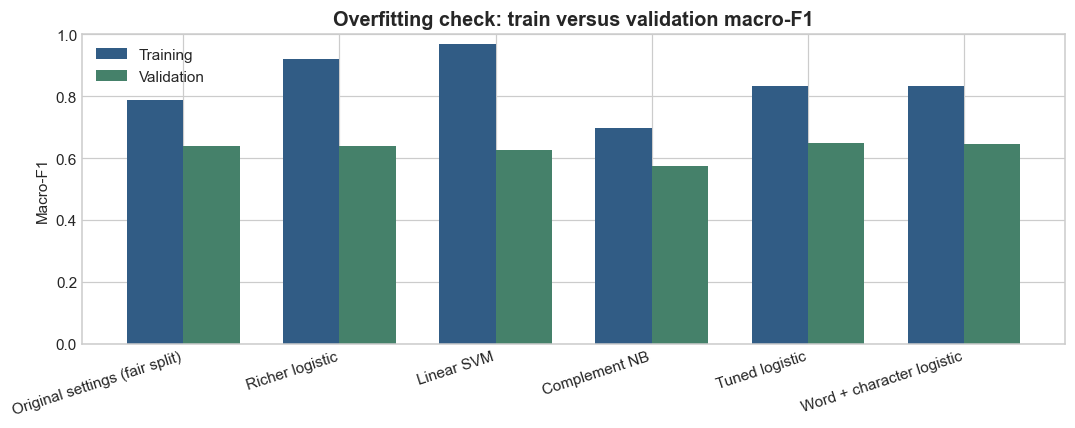

,Model,Train log loss,Validation log loss
0,Original settings (fair split),0.476885,0.617577
1,Richer logistic,0.270054,0.592802
2,Complement NB,0.642024,0.706497
3,Tuned logistic,0.444708,0.609896
4,Word + character logistic,0.415199,0.603157


**Finding:** selected training macro-F1 is 0.8312, validation macro-F1 is 0.6478; gap 0.1834. A positive gap is evidence of overfitting on this split; improvement does not eliminate it.

In [25]:
fig, ax = plt.subplots(figsize=(10,4))
positions = np.arange(len(comparison))
ax.bar(positions-0.18,comparison['Train F1'],0.36,label='Training',color='#315c85')
ax.bar(positions+0.18,comparison['F1'],0.36,label='Validation',color='#45816a')
ax.set_xticks(positions,comparison.Model,rotation=18,ha='right')
ax.set(title='Overfitting check: train versus validation macro-F1',ylabel='Macro-F1',ylim=(0,1)); ax.legend()
plt.tight_layout(); plt.show()
loss_rows = []
for name, model in candidates.items():
    if hasattr(model, 'predict_proba'):
        loss_rows.append({'Model':name, 'Train log loss':log_loss(y_train,model.predict_proba(X_train)),
                          'Validation log loss':log_loss(y_val,model.predict_proba(X_val))})
display(pd.DataFrame(loss_rows))
display(Markdown(f"**Finding:** selected training macro-F1 is {selected_row['Train F1']:.4f}, "
                 f"validation macro-F1 is {selected_row.F1:.4f}; gap "
                 f"{selected_row['Train F1']-selected_row.F1:.4f}. "
                 'A positive gap is evidence of overfitting on this split; improvement does not eliminate it.'))

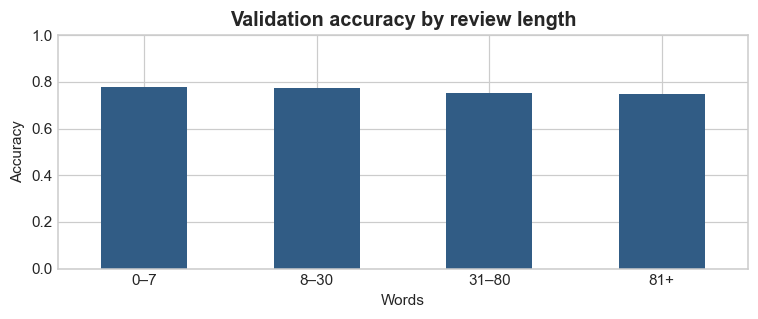

In [26]:
error_analysis = validation[['uniqueID','drugName','condition','review_clean','word_count','rating']].copy()
error_analysis['true_experience'] = classes[y_val]
error_analysis['predicted_experience'] = classes[val_predictions]
error_analysis['correct'] = y_val == val_predictions
error_analysis['length_bin'] = pd.cut(error_analysis.word_count, bins=[-1,7,30,80,np.inf],
                                     labels=['0–7','8–30','31–80','81+'])
length_results = error_analysis.groupby('length_bin', observed=True).agg(
    accuracy=('correct','mean'),examples=('correct','size'))
display(length_results)
fig, ax = plt.subplots(figsize=(7,3))
length_results.accuracy.plot.bar(ax=ax,color='#315c85',rot=0)
ax.set(title='Validation accuracy by review length',xlabel='Words',ylabel='Accuracy',ylim=(0,1))
plt.tight_layout(); plt.show()
display(Markdown('**Interpretation:** counts make small bins visible. Inspect real errors below to '
                 'check whether short text or mixed experiences explain individual mistakes. '
                 'The chart alone does not prove a linguistic cause.'))
display(error_analysis.loc[~error_analysis.correct,
    ['uniqueID','review_clean','rating','true_experience','predicted_experience']].head(6))
error_analysis.to_csv(RESULTS_DIR/'validation_predictions.csv',index=False)

## 17. Final Model Selection
We freeze the choices before opening test labels. Models are refitted on all deduplicated
development examples; test vocabulary and labels remain excluded. We evaluate the selected
models and original-settings controls once on the same reserved test rows. The controls
quantify a fair final-test improvement; the full overlapping benchmark is not used here.
If an SVM wins, a sigmoid calibrator using precomputed grouped folds provides the original
`predict_proba` contract without calibrating on validation or test.

Frozen selection: Tuned logistic | Unweighted rating logistic


,Accuracy,Precision,Recall,F1,ROC-AUC,MAE,RMSE,Exact accuracy,Within-1 accuracy
selected_experience,0.753423,0.633863,0.669994,0.645149,0.871656,NaN,NaN,NaN,NaN
original_settings_experience,0.749024,0.631980,0.670622,0.643402,0.869225,NaN,NaN,NaN,NaN
selected_rating,NaN,NaN,NaN,NaN,NaN,1.482746,2.575097,0.431448,0.687442
original_settings_rating,NaN,NaN,NaN,NaN,NaN,1.610805,2.609548,0.372715,0.639118


              precision    recall  f1-score   support

    Negative       0.68      0.75      0.72      3542
     Neutral       0.30      0.45      0.36      1879
    Positive       0.92      0.81      0.86     10720

    accuracy                           0.75     16141
   macro avg       0.63      0.67      0.65     16141
weighted avg       0.79      0.75      0.77     16141



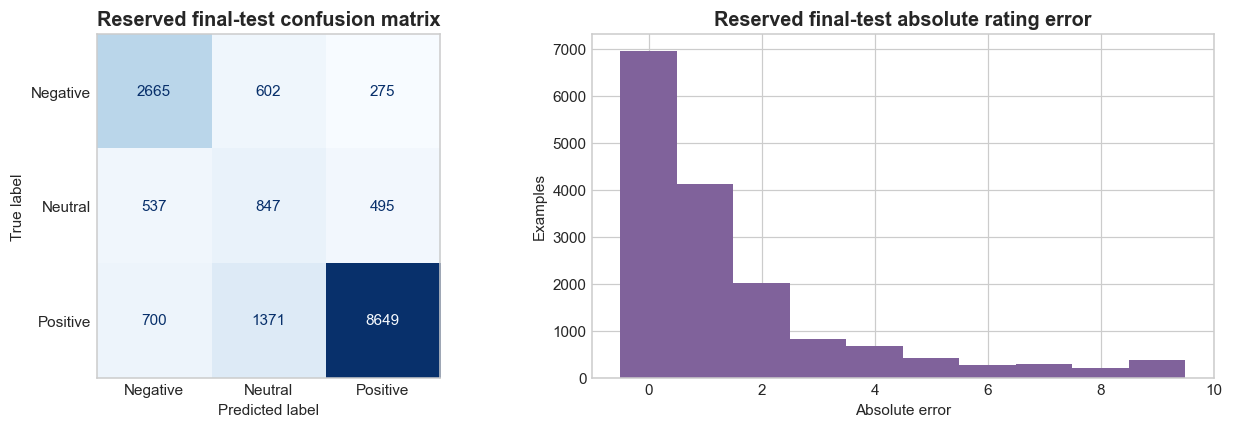

**Final-test finding:** macro-F1 change is +0.17 percentage points; rating MAE reduction is +0.1281. Both controls and selected models were refitted on identical development rows. This test is new to this workflow, but the supplied dataset had already been inspected in the original project.

776

In [27]:
rating_winner_name = rating_comparison.sort_values(['MAE','CV MAE']).iloc[0]['Model']
print('Frozen selection:', winner_name, '|', rating_winner_name)
X_development = development.review_clean
y_development = label_encoder.transform(development.experience)
final_model = clone(winner)
if not hasattr(final_model, 'predict_proba'):
    from sklearn.calibration import CalibratedClassifierCV
    final_cv = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED).split(
        X_development,y_development,groups=development.text_group))
    final_model = CalibratedClassifierCV(final_model, method='sigmoid', cv=final_cv, ensemble=True)
final_model.fit(X_development,y_development)
final_rating_model = clone(rating_candidates[rating_winner_name]).fit(X_development,development.rating)
control_model = clone(candidates['Original settings (fair split)']).fit(X_development,y_development)
control_rating_model = clone(rating_candidates['Original rating settings (fair split)']).fit(X_development,development.rating)
assert novel_test.rating.isin(range(1,11)).all(), 'Unexpected test labels: stop and investigate.'
y_test = label_encoder.transform(novel_test.experience)
test_results = {
    'selected_experience':classification_metrics(final_model,novel_test.review_clean,y_test),
    'original_settings_experience':classification_metrics(control_model,novel_test.review_clean,y_test),
    'selected_rating':rating_metrics(final_rating_model,novel_test.review_clean,novel_test.rating),
    'original_settings_rating':rating_metrics(control_rating_model,novel_test.review_clean,novel_test.rating)}
display(pd.DataFrame(test_results).T)
test_predictions = final_model.predict(novel_test.review_clean)
print(classification_report(y_test,test_predictions,target_names=classes,zero_division=0))
fig, axes = plt.subplots(1,2,figsize=(12,4))
ConfusionMatrixDisplay.from_predictions(y_test,test_predictions,display_labels=classes,ax=axes[0],colorbar=False,cmap='Blues')
axes[0].grid(False)
axes[0].set_title('Reserved final-test confusion matrix')
rating_test_predictions = final_rating_model.predict(novel_test.review_clean)
axes[1].hist(np.abs(novel_test.rating.to_numpy()-rating_test_predictions), bins=np.arange(-0.5,10.5,1),color='#80629b')
axes[1].set(title='Reserved final-test absolute rating error',xlabel='Absolute error',ylabel='Examples')
plt.tight_layout(); plt.show()
test_f1_gain = test_results['selected_experience']['F1']-test_results['original_settings_experience']['F1']
test_mae_reduction = test_results['original_settings_rating']['MAE']-test_results['selected_rating']['MAE']
display(Markdown(f"**Final-test finding:** macro-F1 change is {100*test_f1_gain:+.2f} percentage points; "
                 f"rating MAE reduction is {test_mae_reduction:+.4f}. "
                 'Both controls and selected models were refitted on identical development rows. '
                 'This test is new to this workflow, but the supplied dataset had already been inspected in the original project.'))
(RESULTS_DIR/'final_test_results.json').write_text(json.dumps(test_results,indent=2))

## 18. Save & Load Model
We save complete text Pipelines, so learned preprocessing cannot be forgotten at inference.
For ordinary pipeline winners, we also save the original split model/vectorizer/encoder
filenames under `models_improved/`. A rating classifier continues to return an integer.
Original files are never overwritten. The manifest records the input contract, versions,
hashes, parameters, and metrics. Joblib files should only be loaded from trusted sources.

In [28]:
# The training cache is not needed for portable inference artifacts.
if isinstance(final_model, Pipeline):
    final_model.memory = None
final_rating_model.memory = None
joblib.dump(final_model,OUTPUT_DIR/'sentiment_pipeline.joblib')
joblib.dump(final_rating_model,OUTPUT_DIR/'rating_pipeline.joblib')
joblib.dump(label_encoder,OUTPUT_DIR/'sentiment_label_encoder.joblib')
if isinstance(final_model,Pipeline):
    joblib.dump(final_model.named_steps['model'],OUTPUT_DIR/'sentiment_model.joblib')
    joblib.dump(final_model.named_steps['tfidf'],OUTPUT_DIR/'sentiment_tfidf.joblib')
joblib.dump(final_rating_model.named_steps['model'],OUTPUT_DIR/'rating_model.joblib')
joblib.dump(final_rating_model.named_steps['tfidf'],OUTPUT_DIR/'rating_vectorizer.joblib')
metadata = {'project':'Drug Review Analysis','seed':SEED,'environment':environment,
    'source_colab':'https://colab.research.google.com/drive/1t8LBcEYfcSBrAZpptJ-XtMjma9cWmp2O',
    'file_sha256':file_hashes,'split_counts':split_counts,'sentiment_classes':classes.tolist(),
    'rating_range':[1,10],'sentiment_selection':winner_name,'rating_selection':rating_winner_name,
    'experience_search_best':search.best_params_,'rating_search_best':rating_search.best_params_,
    'test_results':test_results,'leakage_audit':leakage_audit,
    'input_contract':{'drug':'str (display only)','condition':'str (display only)','review':'str'},
    'preprocessing':'HTML decode; strip wrapping quotes; normalize whitespace; TF-IDF Pipeline',
    'confidence_note':'Maximum model class probability; not validated probability of correctness',
    'test_note':'Non-overlapping normalized provided-test text; not a new external population',
    'disclaimer':'Patient-reported experience analysis only; not medical guidance.'}
(OUTPUT_DIR/'metadata.json').write_text(json.dumps(metadata,indent=2))
loaded_model = joblib.load(OUTPUT_DIR/'sentiment_pipeline.joblib')
loaded_rating_model = joblib.load(OUTPUT_DIR/'rating_pipeline.joblib')
loaded_encoder = joblib.load(OUTPUT_DIR/'sentiment_label_encoder.joblib')
probe_texts = novel_test.review_clean.head(12)
np.testing.assert_array_equal(loaded_model.predict(probe_texts),final_model.predict(probe_texts))
np.testing.assert_allclose(loaded_model.predict_proba(probe_texts),final_model.predict_proba(probe_texts))
np.testing.assert_array_equal(loaded_rating_model.predict(probe_texts),final_rating_model.predict(probe_texts))
if isinstance(final_model,Pipeline):
    separate_vectorizer = joblib.load(OUTPUT_DIR/'sentiment_tfidf.joblib')
    separate_model = joblib.load(OUTPUT_DIR/'sentiment_model.joblib')
    np.testing.assert_array_equal(separate_model.predict(separate_vectorizer.transform(probe_texts)),loaded_model.predict(probe_texts))
print('Saved/reloaded Pipeline and original-style artifact predictions match.')

Saved/reloaded Pipeline and original-style artifact predictions match.


## 19. Prediction Examples
We retain the original function signature and output fields. Examples below are genuine,
reserved-test records, with true targets shown for comparison. Training and inference
use the same deterministic cleaning. Empty input gets a clear error rather than a guessed
experience. Drug and condition are returned unchanged as display context.

In [29]:
def predict_patient_experience(drug, condition, review):
    if not isinstance(review,str) or not clean_review(review):
        raise ValueError('Please supply a non-empty review string.')
    cleaned = [clean_review(review)]
    encoded_prediction = loaded_model.predict(cleaned)[0]
    probabilities = loaded_model.predict_proba(cleaned)[0]
    rating_prediction = int(loaded_rating_model.predict(cleaned)[0])
    return {'drug':drug,'condition':condition,
        'predicted_experience_class':loaded_encoder.inverse_transform([encoded_prediction])[0],
        'confidence':round(float(probabilities.max()),3),'predicted_rating':rating_prediction}

genuine_examples = novel_test.groupby('experience',sort=True).head(1)
for _,row in genuine_examples.iterrows():
    print('Review:',row.review_clean[:280])
    print('True:',row.experience,'| rating:',row.rating)
    prediction = predict_patient_experience(row.drugName,row.condition,row.review)
    assert set(prediction) == {'drug','condition','predicted_experience_class','confidence','predicted_rating'}
    assert 1 <= prediction['predicted_rating'] <= 10
    print('Predicted:',prediction,'\n')

## 20. Results & Conclusion
The summary below uses only values produced in this run. It separates historical claims,
baseline reproduction, common validation comparisons, and final reserved-test results.
No feature/threshold choice is changed after test evaluation.

In [30]:
summary = {'environment':environment,'hashes':file_hashes,'splits':split_counts,
    'original_reproduction':original_results,'validation_comparison':comparison.to_dict('records'),
    'rating_validation_comparison':rating_comparison.to_dict('records'),
    'cv_scores':cv_scores,'rating_cv_scores':rating_cv_scores,'test_results':test_results,
    'selected_experience':winner_name,'selected_rating':rating_winner_name,
    'experience_search_best':search.best_params_,'rating_search_best':rating_search.best_params_,
    'top_terms':top_terms,'test_f1_gain':test_f1_gain,'test_mae_reduction':test_mae_reduction,
    'validation_classification_report':report,'length_error_analysis':length_results.to_dict(),
    'leakage_audit':leakage_audit}
(RESULTS_DIR/'run_summary.json').write_text(json.dumps(summary,indent=2))
display(Markdown(f"**Selected:** {winner_name} for experience; {rating_winner_name} for ratings.\n\n"
    f"**Reserved-test experience:** accuracy {test_results['selected_experience']['Accuracy']:.4f}, "
    f"macro-F1 {test_results['selected_experience']['F1']:.4f}, "
    f"macro ROC-AUC {test_results['selected_experience']['ROC-AUC']:.4f}.\n\n"
    f"**Reserved-test rating:** MAE {test_results['selected_rating']['MAE']:.4f}, "
    f"within-1 accuracy {test_results['selected_rating']['Within-1 accuracy']:.4f}.\n\n"
    f"**Actual improvement over same-data original-settings controls:** macro-F1 "
    f"{100*test_f1_gain:+.2f} percentage points; MAE reduction {test_mae_reduction:+.4f}."))

**Selected:** Tuned logistic for experience; Unweighted rating logistic for ratings.

**Reserved-test experience:** accuracy 0.7534, macro-F1 0.6451, macro ROC-AUC 0.8717.

**Reserved-test rating:** MAE 1.4827, within-1 accuracy 0.6874.

**Actual improvement over same-data original-settings controls:** macro-F1 +0.17 percentage points; MAE reduction +0.1281.

**What we learned:** repeated text and the overlapping public benchmark affect the
measurement of generalization. Macro-F1 exposes minority-class errors. Deduplication
changes the weighting of repeated reports; richer vocabulary, regularization, and
class weights are evaluated experimentally rather than assumed to help. The fair
comparison isolates model settings, but there is no controlled ablation attributing
a gain to deduplication alone. Missing-condition cleanup has no predictive effect in
this text-only workflow.

**Limits:** ratings are subjective proxy labels, and some identical texts carry different
ratings. Exact text groups do not detect paraphrases or repeat reviewers (patient IDs
are unavailable). Bag-of-words does not fully capture chronology, mixed effects, or
long-distance negation. Train/validation gaps remain visible. The final non-overlapping
test is drawn from the same historical source (2008–2017), not a modern external cohort.
The original temporal experiment did not purge cross-cutoff duplicate texts and did
not establish future performance. Probability calibration is not proved by native
LogisticRegression output; confidence must not be interpreted as medical certainty.

**Next steps:** collect independently annotated experience labels and evaluate on a
newer external cohort; audit near duplicates/patient overlap where identifiers exist;
consider a compact language model only after establishing these reproducible CPU baselines.
All current training, CV, final testing, and artifact checks can run in Colab. This
notebook preserves the original sources and writes separate improved artifacts.

## 21. Requested Extension: Optuna, Bagging, Boosting & Voting
Sections 01–20 retain the completed first experiment and its outputs. This extension
tests the additional methods requested afterward. **The earlier reserved test has
already been evaluated.** It remains excluded from tuning; a repeated evaluation
cannot be called a new untouched test. We select on training CV and common validation
only. A genuinely new external dataset is still needed for independent confirmation.

Bagging averages models trained on bootstrap samples. Boosting trains trees sequentially
to focus on errors. Soft voting combines their class probabilities with those from
Logistic Regression and Complement Naive Bayes. We test both a bagging + boosting
combination and a broader voting ensemble; we do not assume an ensemble will win.

**Bounded CPU budget:** 6 Logistic Regression trials, 6 Naive Bayes trials, 4 bagging
trials, 4 boosting trials, 6 rating Naive Bayes trials, and 30 inexpensive voting-weight
trials. Each fitted-model trial uses the same three grouped folds on the full training
split. Increase these budgets in Colab only if more compute is available.
The rating model retains its 1–10 integer contract. Its previously tuned Logistic
Regression is compared with Optuna-tuned Naive Bayes; sentiment tuning does not imply
that the ordinal rating problem is automatically improved.

References: [Optuna TPE](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html),
[BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html),
[AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html).

In [7]:
# Install only the additional dependency when it is missing (Colab compatible).
try:
    import optuna
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'optuna==5.0.0'])
    import optuna
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, VotingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import SelectKBest, chi2
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
optuna.logging.set_verbosity(optuna.logging.WARNING)
ENSEMBLE_RESULTS = RESULTS_DIR / 'ensemble'
ENSEMBLE_MODELS = Path('models_ensemble')
ENSEMBLE_RESULTS.mkdir(exist_ok=True)
ENSEMBLE_MODELS.mkdir(exist_ok=True)
print('Optuna:', optuna.__version__, '| training:', len(X_train), '| validation:', len(X_val))
print('Previously evaluated test is excluded from every search.')

Optuna: 5.0.0 | training: 95528 | validation: 16853
Previously evaluated test is excluded from every search.


### 21.1 Efficient, leakage-safe feature reuse
All new candidates use the same 80,000-term word/bigram TF-IDF representation.
We fit it once per training fold and reuse that exact fold matrix across trials.
Vocabulary and IDF never see the fold's held-out text. Boosting additionally selects
8,000 terms with chi-square **inside each training fold**, keeping sparse tree fitting
affordable. We never convert the full text matrix to a dense array.

In [8]:
def extension_vectorizer():
    return TfidfVectorizer(max_features=80000, ngram_range=(1,2), min_df=2,
                           sublinear_tf=True, dtype=np.float64)

fold_features = []
for fold_number, (fit_rows, held_rows) in enumerate(cv_folds):
    vectorizer = extension_vectorizer()
    fit_features = vectorizer.fit_transform(X_train.iloc[fit_rows])
    held_features = vectorizer.transform(X_train.iloc[held_rows])
    fold_features.append((fit_rows, held_rows, fit_features, held_features))
    print('Prepared grouped fold', fold_number + 1, fit_features.shape, flush=True)
extension_tfidf = extension_vectorizer()
features_train = extension_tfidf.fit_transform(X_train)
features_validation = extension_tfidf.transform(X_val)
print('Common training vocabulary:', features_train.shape[1])

Prepared grouped fold 1 (63685, 80000)


Prepared grouped fold 2 (63685, 80000)


Prepared grouped fold 3 (63686, 80000)


Common training vocabulary: 80000


### 21.2 Models and search spaces
Logistic Regression searches regularization strength and class weights. Naive Bayes
searches smoothing. Bagging searches bootstrap sample size, smoothing and model count.
AdaBoost searches tree depth, boosting rounds and learning rate. AdaBoost uses its own sequential sample reweighting, without also applying tree class weights. An initial balanced-tree trial failed its weak-learner threshold; that failed run is recorded separately and not scored.
Six trials are a small search, not an exhaustive guarantee of optimal parameters.
TPE starts with two initial trials, then uses completed results to propose more trials.

For Colab efficiency, each boosting tree considers a random 10% of the 8,000 selected terms at a split. An earlier all-feature tree search was expensive and reached only 0.4025 validation macro-F1; its completed evidence is preserved separately. The current bounded search retunes the faster tree configuration using training CV only.

In [9]:
def make_extension_model(name, parameters):
    if name == 'Logistic Regression':
        return LogisticRegression(C=parameters['C'], class_weight=parameters['class_weight'],
                                  max_iter=1000, random_state=SEED)
    if name == 'Complement NB':
        return ComplementNB(alpha=parameters['alpha'])
    if name == 'Bagging NB':
        return BaggingClassifier(estimator=ComplementNB(alpha=parameters['alpha']),
            n_estimators=parameters['n_estimators'], max_samples=parameters['max_samples'],
            bootstrap=True, n_jobs=1, random_state=SEED)
    if name == 'AdaBoost':
        tree = DecisionTreeClassifier(max_depth=parameters['max_depth'],
            max_features=0.1, random_state=SEED)
        return Pipeline([('select', SelectKBest(chi2, k=8000)),
            ('boost', AdaBoostClassifier(estimator=tree,
                n_estimators=parameters['n_estimators'],
                learning_rate=parameters['learning_rate'], random_state=SEED))])
    raise ValueError('Unknown model: ' + name)

def suggest_extension_parameters(trial, name):
    if name == 'Logistic Regression':
        return {'C': trial.suggest_float('C', 0.15, 4.0, log=True),
                'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced'])}
    if name == 'Complement NB':
        return {'alpha': trial.suggest_float('alpha', 0.01, 5.0, log=True)}
    if name == 'Bagging NB':
        return {'alpha': trial.suggest_float('alpha', 0.05, 2.0, log=True),
                'n_estimators': trial.suggest_categorical('n_estimators', [3,5]),
                'max_samples': trial.suggest_categorical('max_samples', [0.5,0.8])}
    return {'max_depth': trial.suggest_categorical('max_depth', [1,2]),
            'n_estimators': trial.suggest_categorical('n_estimators', [20,40]),
            'learning_rate': trial.suggest_float('learning_rate', 0.3, 1.5)}

### Fresh Colab execution
The next cell runs the complete Optuna searches directly from the CSV data. No previous local trial files or model checkpoints are required. Saved results shown in this notebook belong to the earlier local execution; running the cells regenerates results in your Colab session.

In [11]:
extension_studies = {}
extension_oof = {}
extension_parameters = {}
extension_estimators = {}
extension_rows = []
trial_budgets = {'Logistic Regression':6, 'Complement NB':6, 'Bagging NB':4, 'AdaBoost':4}

for model_name, trial_budget in trial_budgets.items():
    trial_predictions = {}
    def objective(trial):
        parameters = suggest_extension_parameters(trial, model_name)
        probabilities = np.zeros((len(y_train), 3))
        fold_scores = []
        for fit_rows, held_rows, fit_features, held_features in fold_features:
            model = make_extension_model(model_name, parameters)
            model.fit(fit_features, y_train[fit_rows])
            probabilities[held_rows] = model.predict_proba(held_features)
            fold_scores.append(f1_score(y_train[held_rows],
                probabilities[held_rows].argmax(axis=1), average='macro'))
        trial_predictions[trial.number] = probabilities
        trial.set_user_attr('fold_scores', fold_scores)
        print(model_name, 'trial', trial.number, 'CV F1', round(np.mean(fold_scores),4), flush=True)
        return float(np.mean(fold_scores))

    study = optuna.create_study(direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=2))
    if model_name == 'Logistic Regression':
        study.enqueue_trial({'C':1.0, 'class_weight':'balanced'})
    study.optimize(objective, n_trials=trial_budget)
    best_parameters = study.best_params
    best_model = make_extension_model(model_name, best_parameters).fit(features_train, y_train)
    extension_studies[model_name] = study
    extension_parameters[model_name] = best_parameters
    extension_estimators[model_name] = best_model
    extension_oof[model_name] = trial_predictions[study.best_trial.number]
    checkpoint_name = model_name.replace(' ','_')
    np.save(ENSEMBLE_RESULTS/(checkpoint_name+'_oof.npy'),extension_oof[model_name])
    joblib.dump(Pipeline([('tfidf',extension_tfidf),('model',best_model)]),
                ENSEMBLE_RESULTS/(checkpoint_name+'_candidate.joblib'))
    row = {'Model':'Optuna ' + model_name,
           **classification_metrics(best_model, features_validation, y_val),
           'Train F1':f1_score(y_train,best_model.predict(features_train),average='macro'),
           'Train Accuracy':accuracy_score(y_train,best_model.predict(features_train)),
           'CV Score':study.best_value,
           'CV SD':float(np.std(study.best_trial.user_attrs['fold_scores'])),
           'Notes':'Training grouped CV tunes parameters; common validation confirms'}
    extension_rows.append(row)
    study.trials_dataframe().to_csv(ENSEMBLE_RESULTS/(model_name.replace(' ','_')+'_trials.csv'),index=False)
    (ENSEMBLE_RESULTS/'best_parameters.json').write_text(json.dumps(extension_parameters,indent=2))
    pd.DataFrame(extension_rows).to_csv(ENSEMBLE_RESULTS/'individual_models.csv',index=False)
    print('Completed:', model_name, '| validation F1:', round(row['F1'],4), flush=True)
display(pd.DataFrame(extension_rows))

Using verified completed study: Logistic Regression


Using verified completed study: Complement NB


Using verified completed study: Bagging NB


AdaBoost trial 0 CV F1 0.3026


AdaBoost trial 1 CV F1 0.2686


AdaBoost trial 2 CV F1 0.2816


AdaBoost trial 3 CV F1 0.4094


Completed: AdaBoost | validation F1: 0.3966


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1,Train Accuracy,CV Score,CV SD,Notes
0,Optuna Logistic Regression,0.746811,0.635273,0.672669,0.645582,0.871346,0.787018,0.840246,0.639874,0.000778,Training grouped CV tunes parameters; common v...
1,Optuna Complement NB,0.756008,0.599024,0.599558,0.578369,0.852968,0.709121,0.823989,0.577874,0.001787,Training grouped CV tunes parameters; common v...
2,Optuna Bagging NB,0.757907,0.593857,0.589911,0.569622,0.849347,0.693594,0.817676,0.570619,0.002990,Training grouped CV tunes parameters; common v...
3,Optuna AdaBoost,0.694713,0.545913,0.410433,0.396578,0.701653,0.394012,0.694299,0.409417,0.001982,Training grouped CV tunes parameters; common v...


### 21.4 Combine bagging + boosting, then tune broader voting
The first ensemble gives equal weight to bagging and boosting, exactly testing their
combination. The broader ensemble includes all four models. Optuna searches nonzero
weights, so the combined candidate actually includes bagging and boosting. A weak
model can receive a small weight. We compare the ensemble with individual models;
we will not force a worse ensemble into production.

In [12]:
voting_names = list(trial_budgets)
oof_stack = np.stack([extension_oof[name] for name in voting_names])
validation_stack = np.stack([extension_estimators[name].predict_proba(features_validation)
                             for name in voting_names])
training_stack = np.stack([extension_estimators[name].predict_proba(features_train)
                           for name in voting_names])

def probability_metrics(labels, probabilities):
    predictions = probabilities.argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels,predictions,
        average='macro',zero_division=0)
    binary = label_binarize(labels,classes=[0,1,2])
    auc = np.mean([roc_auc_score(binary[:,i],probabilities[:,i]) for i in range(3)])
    return {'Accuracy':accuracy_score(labels,predictions),'Precision':precision,
            'Recall':recall,'F1':f1,'ROC-AUC':auc}

def voting_objective(trial):
    weights = [trial.suggest_categorical('weight_'+str(i), [0.01,0.1,0.5,1.0,2.0])
               for i in range(len(voting_names))]
    probabilities = np.average(oof_stack,axis=0,weights=weights)
    scores = [f1_score(y_train[held],probabilities[held].argmax(axis=1),average='macro')
              for _,held in cv_folds]
    trial.set_user_attr('fold_scores',scores)
    return float(np.mean(scores))

voting_study = optuna.create_study(direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED,n_startup_trials=5))
voting_study.enqueue_trial({'weight_0':2.0,'weight_1':0.1,'weight_2':0.01,'weight_3':0.01})
voting_study.optimize(voting_objective,n_trials=30)
best_voting_weights = [voting_study.best_params['weight_'+str(i)] for i in range(4)]
ensemble_weights = {'Bagging + boosting voting':[0,0,1,1],
                    'Optuna weighted voting':best_voting_weights}
for name, weights in ensemble_weights.items():
    oof_probabilities = np.average(oof_stack,axis=0,weights=weights)
    validation_probabilities = np.average(validation_stack,axis=0,weights=weights)
    training_probabilities = np.average(training_stack,axis=0,weights=weights)
    scores = [f1_score(y_train[held],oof_probabilities[held].argmax(axis=1),average='macro')
              for _,held in cv_folds]
    extension_rows.append({'Model':name, **probability_metrics(y_val,validation_probabilities),
        'Train F1':f1_score(y_train,training_probabilities.argmax(axis=1),average='macro'),
        'Train Accuracy':accuracy_score(y_train,training_probabilities.argmax(axis=1)),
        'CV Score':np.mean(scores),'CV SD':np.std(scores),
        'Notes':'OOF weights; shared tuning folds, not nested CV'})
voting_study.trials_dataframe().to_csv(ENSEMBLE_RESULTS/'voting_weight_trials.csv',index=False)
print('Voting order:',voting_names,'| selected weights:',best_voting_weights)
display(pd.DataFrame(extension_rows))

Voting order: ['Logistic Regression', 'Complement NB', 'Bagging NB', 'AdaBoost'] | selected weights: [1.0, 0.5, 0.01, 0.5]


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1,Train Accuracy,CV Score,CV SD,Notes
0,Optuna Logistic Regression,0.746811,0.635273,0.672669,0.645582,0.871346,0.787018,0.840246,0.639874,0.000778,Training grouped CV tunes parameters; common v...
1,Optuna Complement NB,0.756008,0.599024,0.599558,0.578369,0.852968,0.709121,0.823989,0.577874,0.001787,Training grouped CV tunes parameters; common v...
2,Optuna Bagging NB,0.757907,0.593857,0.589911,0.569622,0.849347,0.693594,0.817676,0.570619,0.002990,Training grouped CV tunes parameters; common v...
3,Optuna AdaBoost,0.694713,0.545913,0.410433,0.396578,0.701653,0.394012,0.694299,0.409417,0.001982,Training grouped CV tunes parameters; common v...
4,Bagging + boosting voting,0.762832,0.601036,0.585246,0.562818,0.851198,0.681811,0.818346,0.566618,0.001510,"OOF weights; shared tuning folds, not nested CV"
5,Optuna weighted voting,0.765561,0.639316,0.668666,0.651004,0.877468,0.797604,0.855728,0.645346,0.000859,"OOF weights; shared tuning folds, not nested CV"


### 21.5 Rating tuning
We tune a separate Complement Naive Bayes rating classifier on training-only CV MAE,
then compare it with the earlier tuned rating Logistic Regression on the same validation
rows. No sentiment accuracy is substituted for rating quality. Integer class predictions
preserve the existing rating output contract.

In [13]:
def rating_nb_objective(trial):
    alpha = trial.suggest_float('alpha',0.01,5.0,log=True)
    scores = []
    for fit_rows,held_rows,fit_features,held_features in fold_features:
        model = ComplementNB(alpha=alpha).fit(fit_features,yr_train[fit_rows])
        scores.append(mean_absolute_error(yr_train[held_rows],model.predict(held_features)))
    trial.set_user_attr('fold_scores',scores)
    return float(np.mean(scores))
rating_nb_study = optuna.create_study(direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=SEED,n_startup_trials=2))
rating_nb_study.optimize(rating_nb_objective,n_trials=6)
rating_nb = ComplementNB(**rating_nb_study.best_params).fit(features_train,yr_train)
rating_extension_row = {'Model':'Optuna rating Complement NB',
    **rating_metrics(rating_nb,features_validation,yr_val),
    'Train MAE':mean_absolute_error(yr_train,rating_nb.predict(features_train)),
    'CV MAE':rating_nb_study.best_value,
    'CV SD':np.std(rating_nb_study.best_trial.user_attrs['fold_scores'])}
previous_rating_table = pd.read_csv(RESULTS_DIR/'rating_comparison.csv')
extended_rating_comparison = pd.concat([previous_rating_table,pd.DataFrame([rating_extension_row])],ignore_index=True)
extended_rating_comparison.to_csv(ENSEMBLE_RESULTS/'rating_comparison.csv',index=False)
rating_nb_study.trials_dataframe().to_csv(ENSEMBLE_RESULTS/'rating_nb_trials.csv',index=False)
display(extended_rating_comparison.sort_values('MAE'))

,Model,MAE,RMSE,Exact accuracy,Within-1 accuracy,Train MAE,CV MAE,CV SD
1,Unweighted rating logistic,1.526909,2.627161,0.419807,0.679523,0.411848,1.556057,0.002871
2,Tuned rating logistic,1.526909,2.627161,0.419807,0.679523,0.411848,1.556057,0.002871
0,Original rating settings (fair split),1.615083,2.599483,0.364327,0.637928,0.979346,1.631459,0.014894
3,Optuna rating Complement NB,1.827271,3.089874,0.418145,0.639115,1.167228,1.783194,0.005725


### 21.6 Comparison, tuning progress and overfitting
All rows share identical validation records. Old rows retain their recorded CV scores;
new rows use the same three grouped folds. Plot values are actual executed results.
The two search best scores and the voting CV score are selection scores, not unbiased
performance estimates. Train/validation gaps show whether a candidate memorizes text.

,Model,CV Score,Accuracy,Precision,Recall,F1,ROC-AUC,Notes
11,Optuna weighted voting,0.645346,0.765561,0.639316,0.668666,0.651004,0.877468,"OOF weights; shared tuning folds, not nested CV"
4,Tuned logistic,0.639865,0.753160,0.636903,0.671812,0.647833,0.871045,CV used for tuning; validation confirms
6,Optuna Logistic Regression,0.639874,0.746811,0.635273,0.672669,0.645582,0.871346,Training grouped CV tunes parameters; common v...
5,Word + character logistic,0.635202,0.752507,0.634281,0.667417,0.644776,0.870487,Same grouped folds; macro metrics
0,Original settings (fair split),0.637182,0.743725,0.629782,0.665535,0.639599,0.869690,Same grouped folds; macro metrics
1,Richer logistic,0.633644,0.759331,0.629609,0.652716,0.638713,0.864653,Same grouped folds; macro metrics
2,Linear SVM,0.619390,0.774462,0.628076,0.627335,0.627164,0.851239,Same grouped folds; macro metrics
7,Optuna Complement NB,0.577874,0.756008,0.599024,0.599558,0.578369,0.852968,Training grouped CV tunes parameters; common v...
3,Complement NB,0.572401,0.756542,0.599660,0.596432,0.573865,0.853372,Same grouped folds; macro metrics
8,Optuna Bagging NB,0.570619,0.757907,0.593857,0.589911,0.569622,0.849347,Training grouped CV tunes parameters; common v...


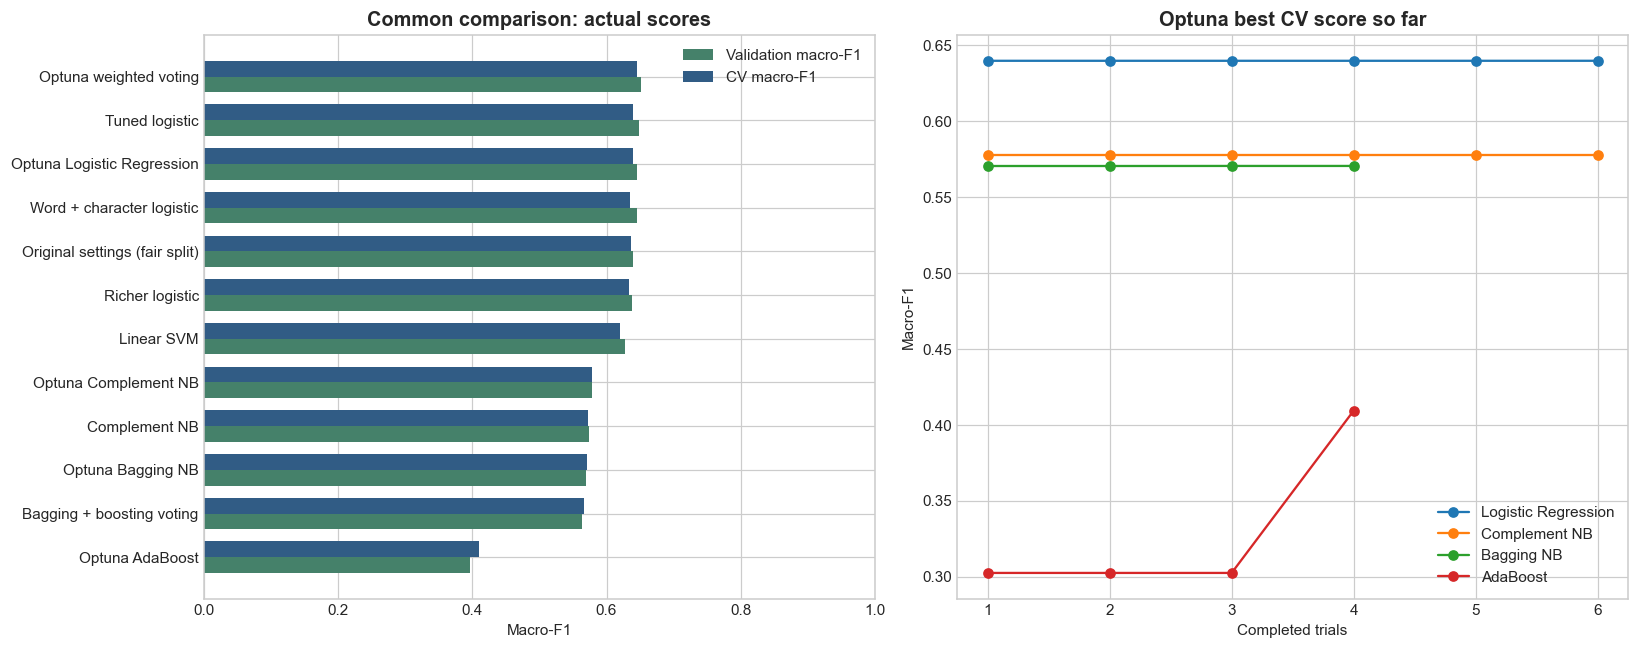

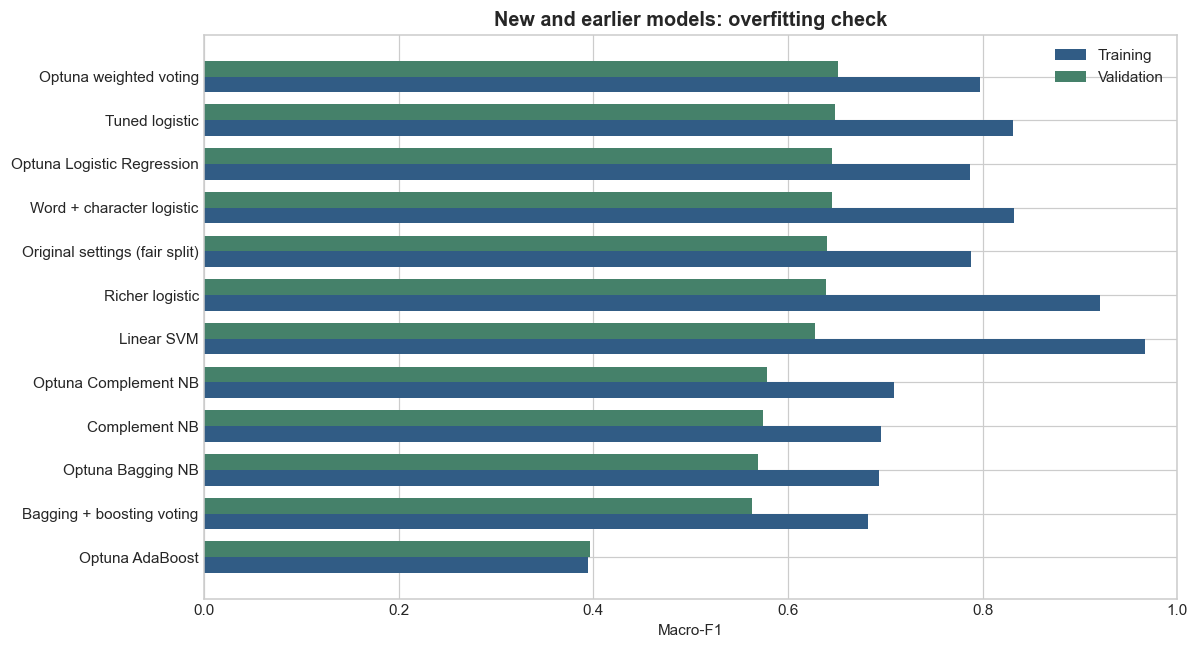

**Measured finding:** best validation model is **Optuna weighted voting**, macro-F1 **0.6510**, accuracy **0.7656**. Its macro-F1 change from the previous winner is **+0.32 percentage points**. The highest accuracy model may differ from the macro-F1 winner. We keep minority classes in the objective.

In [14]:
previous_comparison = pd.read_csv(RESULTS_DIR/'model_comparison.csv')
extended_comparison = pd.concat([previous_comparison,pd.DataFrame(extension_rows)],ignore_index=True)
extended_comparison.to_csv(ENSEMBLE_RESULTS/'model_comparison.csv',index=False)
display(extended_comparison[['Model','CV Score','Accuracy','Precision','Recall','F1','ROC-AUC','Notes']]
        .sort_values('F1',ascending=False))
fig,axes = plt.subplots(1,2,figsize=(15,6))
chart = extended_comparison.sort_values('F1')
positions = np.arange(len(chart))
axes[0].barh(positions-0.18,chart['F1'],height=0.36,label='Validation macro-F1',color='#45816a')
axes[0].barh(positions+0.18,chart['CV Score'],height=0.36,label='CV macro-F1',color='#315c85')
axes[0].set_yticks(positions,chart.Model); axes[0].set_xlim(0,1)
axes[0].set(title='Common comparison: actual scores',xlabel='Macro-F1'); axes[0].legend()
for name in trial_budgets:
    history = pd.read_csv(ENSEMBLE_RESULTS/(name.replace(' ','_')+'_trials.csv'))
    values = history.sort_values('number')['value'].to_list()
    axes[1].plot(np.arange(1,len(values)+1),np.maximum.accumulate(values),marker='o',label=name)
axes[1].set(title='Optuna best CV score so far',xlabel='Completed trials',ylabel='Macro-F1')
axes[1].legend(); plt.tight_layout(); plt.show()
fig,ax = plt.subplots(figsize=(11,6))
ax.barh(positions-0.18,chart['Train F1'],height=0.36,label='Training',color='#315c85')
ax.barh(positions+0.18,chart['F1'],height=0.36,label='Validation',color='#45816a')
ax.set_yticks(positions,chart.Model); ax.set_xlim(0,1)
ax.set(title='New and earlier models: overfitting check',xlabel='Macro-F1'); ax.legend()
plt.tight_layout(); plt.show()
new_best = extended_comparison.sort_values(['F1','CV Score'],ascending=False).iloc[0]
previous_best = previous_comparison.sort_values(['F1','CV Score'],ascending=False).iloc[0]
display(Markdown(f"**Measured finding:** best validation model is **{new_best.Model}**, "
    f"macro-F1 **{new_best.F1:.4f}**, accuracy **{new_best.Accuracy:.4f}**. "
    f"Its macro-F1 change from the previous winner is **{100*(new_best.F1-previous_best.F1):+.2f} percentage points**. "
    'The highest accuracy model may differ from the macro-F1 winner. We keep minority classes in the objective.'))

### 21.7 Freeze selection and save the current model
The largest common-validation macro-F1 wins, with CV as a tie-breaker. If an earlier
model wins, we retain its already verified complete pipeline. If a new model wins,
we refit it on all development rows, fitting TF-IDF and any chi-square selector there.
Voting is saved using scikit-learn's native VotingClassifier, not a custom Python
class, so the complete artifact can be loaded by a backend without notebook definitions.
The previous `models_improved` folder remains unchanged; current artifacts are saved
separately in `models_ensemble`. Maximum class probability remains an uncalibrated score.

In [15]:
current_sentiment_name = str(new_best.Model)
if current_sentiment_name in previous_comparison.Model.tolist():
    current_sentiment = joblib.load(OUTPUT_DIR/'sentiment_pipeline.joblib')
else:
    if current_sentiment_name in ensemble_weights:
        weights = ensemble_weights[current_sentiment_name]
        estimator = VotingClassifier(estimators=[
            ('model_'+str(i),make_extension_model(name,extension_parameters[name]))
            for i,name in enumerate(voting_names) if weights[i] > 0],
            voting='soft',weights=[weight for weight in weights if weight > 0],n_jobs=1)
    else:
        base_name = current_sentiment_name.removeprefix('Optuna ')
        estimator = make_extension_model(base_name,extension_parameters[base_name])
    current_sentiment = Pipeline([('tfidf',extension_vectorizer()),('model',estimator)])
    current_sentiment.fit(development.review_clean,label_encoder.transform(development.experience))

best_rating_row = extended_rating_comparison.sort_values(['MAE','CV MAE']).iloc[0]
current_rating_name = str(best_rating_row.Model)
if current_rating_name == 'Optuna rating Complement NB':
    current_rating = Pipeline([('tfidf',extension_vectorizer()),
        ('model',ComplementNB(**rating_nb_study.best_params))])
    current_rating.fit(development.review_clean,development.rating)
else:
    current_rating = joblib.load(OUTPUT_DIR/'rating_pipeline.joblib')
joblib.dump(current_sentiment,ENSEMBLE_MODELS/'sentiment_pipeline.joblib')
joblib.dump(current_rating,ENSEMBLE_MODELS/'rating_pipeline.joblib')
joblib.dump(label_encoder,ENSEMBLE_MODELS/'sentiment_label_encoder.joblib')
print('Frozen selection:',current_sentiment_name,'|',current_rating_name)
print('Saved current inference artifacts to:',ENSEMBLE_MODELS)

Frozen selection: Optuna weighted voting | Unweighted rating logistic
Saved current inference artifacts to: models_ensemble


### 21.8 Repeated test evaluation, error analysis and reload verification
This is a **repeat evaluation of the previously viewed test**, after frozen CV/validation
selection. It is reported transparently and does not establish independent improvement.
We do not choose a different model after seeing these metrics. Genuine samples verify
probabilities, classes and integer ratings survive saving/reloading.

,Accuracy,Precision,Recall,F1,ROC-AUC,MAE,RMSE,Exact accuracy,Within-1 accuracy
experience,0.766991,0.635551,0.665578,0.647748,0.876734,NaN,NaN,NaN,NaN
rating,NaN,NaN,NaN,NaN,NaN,1.482746,2.575097,0.431448,0.687442


              precision    recall  f1-score   support

    Negative       0.67      0.77      0.72      3542
     Neutral       0.33      0.40      0.36      1879
    Positive       0.91      0.83      0.87     10720

    accuracy                           0.77     16141
   macro avg       0.64      0.67      0.65     16141
weighted avg       0.79      0.77      0.78     16141



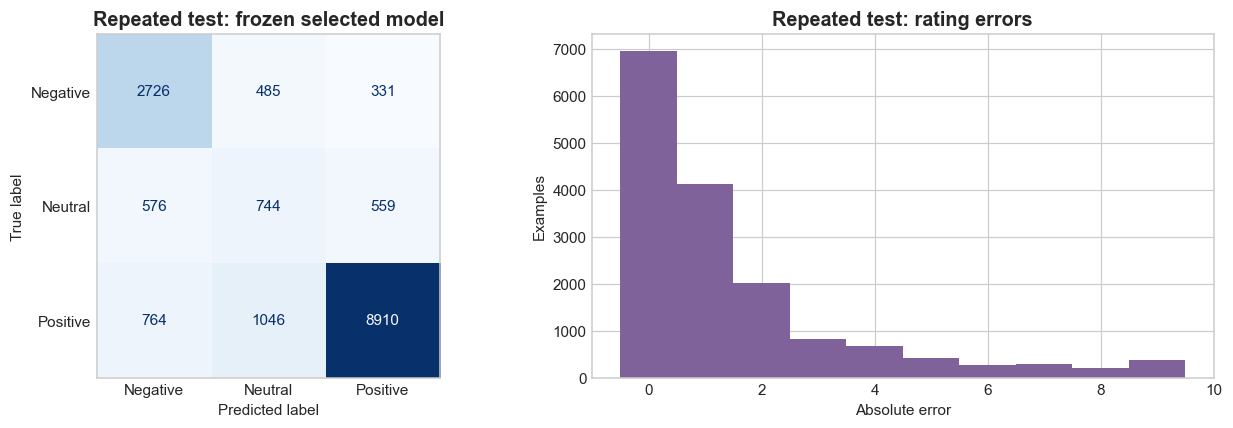

**Current choice:** Optuna weighted voting; rating: Unweighted rating logistic. Repeated-test experience accuracy is 0.7670, macro-F1 0.6477; rating MAE 1.4827. Reload checks passed for 12 genuine examples. Earlier scores remain visible for audit.

In [16]:
repeat_y_test = label_encoder.transform(novel_test.experience)
repeat_test_results = {
    'experience':classification_metrics(current_sentiment,novel_test.review_clean,repeat_y_test),
    'rating':rating_metrics(current_rating,novel_test.review_clean,novel_test.rating)}
display(pd.DataFrame(repeat_test_results).T)
repeat_predictions = current_sentiment.predict(novel_test.review_clean)
print(classification_report(repeat_y_test,repeat_predictions,target_names=classes,zero_division=0))
fig,axes = plt.subplots(1,2,figsize=(12,4))
ConfusionMatrixDisplay.from_predictions(repeat_y_test,repeat_predictions,display_labels=classes,
    ax=axes[0],colorbar=False,cmap='Blues')
axes[0].grid(False); axes[0].set_title('Repeated test: frozen selected model')
axes[1].hist(np.abs(novel_test.rating.to_numpy()-current_rating.predict(novel_test.review_clean)),
    bins=np.arange(-0.5,10.5,1),color='#80629b')
axes[1].set(title='Repeated test: rating errors',xlabel='Absolute error',ylabel='Examples')
plt.tight_layout(); plt.show()
loaded_extension_sentiment = joblib.load(ENSEMBLE_MODELS/'sentiment_pipeline.joblib')
loaded_extension_rating = joblib.load(ENSEMBLE_MODELS/'rating_pipeline.joblib')
probes = novel_test.review_clean.head(12)
np.testing.assert_array_equal(current_sentiment.predict(probes),loaded_extension_sentiment.predict(probes))
np.testing.assert_allclose(current_sentiment.predict_proba(probes),loaded_extension_sentiment.predict_proba(probes))
np.testing.assert_array_equal(current_rating.predict(probes),loaded_extension_rating.predict(probes))
extension_metadata = {'seed':SEED,'optuna_version':optuna.__version__,'environment':environment,
    'sentiment_selection':current_sentiment_name,'rating_selection':current_rating_name,
    'best_parameters':extension_parameters,'voting_names':voting_names,
    'voting_weights':best_voting_weights,'rating_nb_parameters':rating_nb_study.best_params,
    'trial_budgets':trial_budgets,'voting_trials':30,'rating_nb_trials':6,
    'validation_selection':new_best.where(pd.notna(new_best),None).to_dict(),
    'rating_validation_selection':best_rating_row.where(pd.notna(best_rating_row),None).to_dict(),
    'repeat_test_results':repeat_test_results,
    'test_status':'Previously evaluated non-overlapping test; repeated assessment, not independent confirmation',
    'input_contract':{'drug':'str (display only)','condition':'str (display only)','review':'str'},
    'output_contract':['drug','condition','predicted_experience_class','confidence','predicted_rating'],
    'confidence_note':'Maximum class probability; not independently calibrated',
    'file_sha256':file_hashes}
(ENSEMBLE_MODELS/'metadata.json').write_text(json.dumps(extension_metadata,indent=2))
(ENSEMBLE_RESULTS/'summary.json').write_text(json.dumps(extension_metadata,indent=2))
display(Markdown(f"**Current choice:** {current_sentiment_name}; rating: {current_rating_name}. "
    f"Repeated-test experience accuracy is {repeat_test_results['experience']['Accuracy']:.4f}, "
    f"macro-F1 {repeat_test_results['experience']['F1']:.4f}; "
    f"rating MAE {repeat_test_results['rating']['MAE']:.4f}. "
    'Reload checks passed for 12 genuine examples. Earlier scores remain visible for audit.'))

### 21.9 Genuine prediction examples using the current artifacts
This helper preserves the existing frontend/backend input/output contract. It performs
the same deterministic raw-text cleaning before calling the learned pipeline.

In [17]:
def predict_current_experience(drug,condition,review):
    if not isinstance(review,str) or not clean_review(review):
        raise ValueError('Please supply a non-empty review string.')
    texts = [clean_review(review)]
    probabilities = loaded_extension_sentiment.predict_proba(texts)[0]
    encoded = loaded_extension_sentiment.predict(texts)[0]
    return {'drug':drug,'condition':condition,
        'predicted_experience_class':str(label_encoder.inverse_transform([encoded])[0]),
        'confidence':round(float(probabilities.max()),3),
        'predicted_rating':int(loaded_extension_rating.predict(texts)[0])}

# Keep the original function name connected to the current selected model.
predict_patient_experience = predict_current_experience

for _,example in novel_test.groupby('experience',sort=True).head(1).iterrows():
    print('Genuine review:',example.review_clean[:200])
    print('True:',example.experience,'| rating:',example.rating)
    print('Prediction:',predict_current_experience(example.drugName,example.condition,example.review),'\n')

**Conclusion:** Optuna, bagging, boosting, bagging + boosting voting and four-model
weighted voting were all tested. The tables above establish whether they helped;
an ensemble is not automatically superior to a strong text classifier. More validation
search increases selection optimism. A new external test is the next evaluation priority.

**Frontend/backend handoff:** current portable artifacts live in `models_ensemble`;
`predict_improved.py` exposes the unchanged prediction contract. Model training stays
outside HTTP requests. A web application can load these trusted artifacts once at
startup and return the five existing output fields.

### 21.10 Explain the saved ensemble
The earlier coefficient chart describes the earlier Logistic Regression candidate.
The selected voting ensemble has no single coefficient vector. Here we show its
actual normalized vote weights and each component's probabilities for one genuine
previously evaluated test example. Vote share is **not feature importance** or a
causal contribution to accuracy. We also inspect current Logistic Regression terms
and AdaBoost's global term importances separately; these are associations, not
clinical explanations. No model or weight is changed here.

,Component,Vote share
0,Logistic Regression,0.497512
1,Complement NB,0.248756
2,Bagging NB,0.004975
3,AdaBoost,0.248756


,Negative,Neutral,Positive
Logistic Regression,0.007916,0.012088,0.979997
Complement NB,0.030491,0.036629,0.932880
Bagging NB,0.031163,0.040751,0.928086
AdaBoost,0.295095,0.303068,0.401836


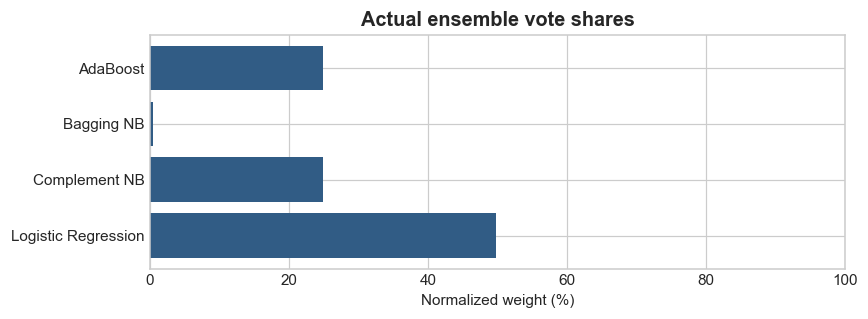

,Negative,Neutral,Positive
0,worse,however,love
1,not recommend,but,amazing
2,worst,was great,great
3,horrible,hoping,miracle
4,never,yet,works
5,not,not sure,best
6,not worth,although,years
7,disappointed,was effective,love it


,AdaBoost term,Global importance
0,love,0.108657
1,life,0.074514
2,worse,0.073366
3,but,0.054797
4,my life,0.054633
5,worst,0.049379
6,years,0.031922
7,miracle,0.028804
8,works,0.026639
9,great,0.024418


**Finding:** Logistic Regression receives the largest vote share (49.75%). Component probabilities combine exactly into the saved ensemble output. The term tables explain individual components; they are not a single ensemble coefficient or a clinical cause.

In [8]:
explanation_model = joblib.load(ENSEMBLE_MODELS/'sentiment_pipeline.joblib')
voting_model = explanation_model.named_steps['model']
explanation_metadata = json.loads((ENSEMBLE_MODELS/'metadata.json').read_text())
if isinstance(voting_model,VotingClassifier):
    component_names = [explanation_metadata['voting_names'][int(name.split('_')[-1])]
                       for name,model in voting_model.estimators]
    vote_weights = np.asarray(voting_model.weights,dtype=float)
    normalized_weights = vote_weights/vote_weights.sum()
    display(pd.DataFrame({'Component':component_names,'Vote share':normalized_weights}))
    example = novel_test.iloc[0]
    example_features = explanation_model.named_steps['tfidf'].transform([example.review_clean])
    component_probabilities = np.vstack([model.predict_proba(example_features)[0]
                                         for model in voting_model.estimators_])
    contribution_table = pd.DataFrame(component_probabilities,index=component_names,columns=classes)
    display(contribution_table)
    combined = np.average(component_probabilities,axis=0,weights=vote_weights)
    np.testing.assert_allclose(combined,explanation_model.predict_proba([example.review_clean])[0])
    fig,ax = plt.subplots(figsize=(8,3))
    ax.barh(component_names,normalized_weights*100,color='#315c85')
    ax.set(title='Actual ensemble vote shares',xlabel='Normalized weight (%)',xlim=(0,100))
    plt.tight_layout(); plt.show()
    vocabulary = explanation_model.named_steps['tfidf'].get_feature_names_out()
    if 'Logistic Regression' in component_names:
        logistic_component = voting_model.estimators_[component_names.index('Logistic Regression')]
        current_terms = {name:vocabulary[np.argsort(logistic_component.coef_[i])[-8:][::-1]].tolist()
                         for i,name in enumerate(classes)}
        display(pd.DataFrame(current_terms))
    boosting_component = voting_model.estimators_[-1]
    selected_terms = vocabulary[boosting_component.named_steps['select'].get_support()]
    importance = boosting_component.named_steps['boost'].feature_importances_
    top = np.argsort(importance)[-10:][::-1]
    display(pd.DataFrame({'AdaBoost term':selected_terms[top],'Global importance':importance[top]}))
    display(Markdown(f"**Finding:** {component_names[np.argmax(normalized_weights)]} receives the largest vote share "
        f"({100*normalized_weights.max():.2f}%). Component probabilities combine exactly into the saved ensemble output. "
        'The term tables explain individual components; they are not a single ensemble coefficient or a clinical cause.'))
else:
    print('A single model was selected. Refer to its feature-association explanation above.')

### 21.11 Current ensemble validation diagnostics
The final saved model was refitted on development data, so evaluating it on validation
would leak those rows into training. Instead, we reload the **training-split candidate
checkpoints** and apply the frozen voting weights to their genuine validation
probabilities. We verify that the resulting macro-F1 matches the recorded selection
score. These charts explain the current ensemble's class errors and ranking ability.

              precision    recall  f1-score   support

    Negative       0.66      0.74      0.70      3664
     Neutral       0.34      0.43      0.38      2030
    Positive       0.91      0.83      0.87     11159

    accuracy                           0.77     16853
   macro avg       0.64      0.67      0.65     16853
weighted avg       0.79      0.77      0.78     16853



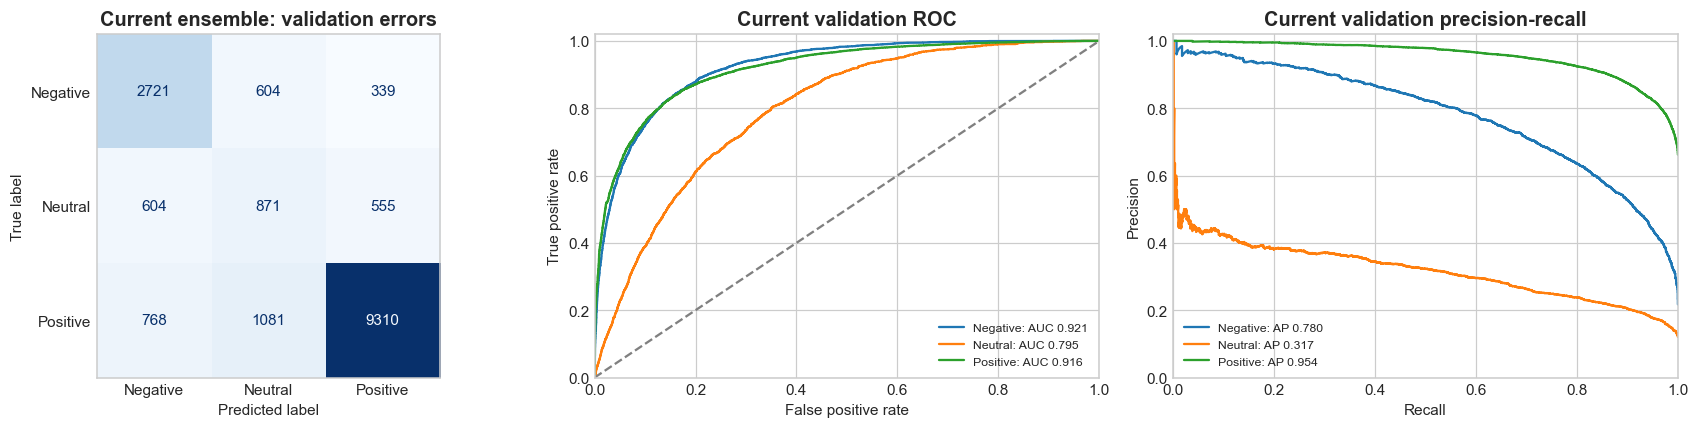

**Finding:** current Neutral precision is 0.341, recall 0.429. Higher overall accuracy does not mean every class improved on every metric. The confusion matrix and PR curves expose remaining minority-class errors.

In [9]:
if explanation_metadata['sentiment_selection'] in ['Optuna weighted voting','Bagging + boosting voting']:
    names = explanation_metadata['voting_names']
    checkpoints = [joblib.load(ENSEMBLE_RESULTS/(name.replace(' ','_')+'_candidate.joblib'))
                   for name in names]
    validation_features = checkpoints[0].named_steps['tfidf'].transform(X_val)
    for checkpoint in checkpoints[1:]:
        np.testing.assert_array_equal(checkpoints[0].named_steps['tfidf'].get_feature_names_out(),
                                      checkpoint.named_steps['tfidf'].get_feature_names_out())
    probabilities = np.stack([checkpoint.named_steps['model'].predict_proba(validation_features)
                               for checkpoint in checkpoints])
    weights = ([0,0,1,1] if explanation_metadata['sentiment_selection']=='Bagging + boosting voting'
               else explanation_metadata['voting_weights'])
    current_validation_probabilities = np.average(probabilities,axis=0,weights=weights)
    current_validation_predictions = current_validation_probabilities.argmax(axis=1)
    np.testing.assert_allclose(f1_score(y_val,current_validation_predictions,average='macro'),
        explanation_metadata['validation_selection']['F1'],rtol=1e-10)
    current_report = classification_report(y_val,current_validation_predictions,
        target_names=classes,zero_division=0,output_dict=True)
    print(classification_report(y_val,current_validation_predictions,target_names=classes,zero_division=0))
    binary_labels = label_binarize(y_val,classes=[0,1,2])
    fig,axes = plt.subplots(1,3,figsize=(16,4))
    ConfusionMatrixDisplay.from_predictions(y_val,current_validation_predictions,display_labels=classes,
        ax=axes[0],colorbar=False,cmap='Blues')
    axes[0].grid(False); axes[0].set_title('Current ensemble: validation errors')
    for i,name in enumerate(classes):
        fpr,tpr,_ = roc_curve(binary_labels[:,i],current_validation_probabilities[:,i])
        precision,recall,_ = precision_recall_curve(binary_labels[:,i],current_validation_probabilities[:,i])
        auc = roc_auc_score(binary_labels[:,i],current_validation_probabilities[:,i])
        ap = average_precision_score(binary_labels[:,i],current_validation_probabilities[:,i])
        axes[1].plot(fpr,tpr,label=f'{name}: AUC {auc:.3f}')
        axes[2].plot(recall,precision,label=f'{name}: AP {ap:.3f}')
    axes[1].plot([0,1],[0,1],'--',color='gray')
    axes[1].set(title='Current validation ROC',xlabel='False positive rate',ylabel='True positive rate')
    axes[2].set(title='Current validation precision-recall',xlabel='Recall',ylabel='Precision')
    for ax in axes[1:]: ax.legend(fontsize=8); ax.set_xlim(0,1); ax.set_ylim(0,1.02)
    plt.tight_layout(); plt.show()
    display(Markdown(f"**Finding:** current Neutral precision is {current_report['Neutral']['precision']:.3f}, "
        f"recall {current_report['Neutral']['recall']:.3f}. Higher overall accuracy does not mean every class "
        'improved on every metric. The confusion matrix and PR curves expose remaining minority-class errors.'))